# Crop Phenology Prediction: Standalone Baselines Evaluation (LOYOCV)
Evaluates standalone environmental and spectral baselines (`B1`–`B5`) using Random Forest and XGBoost across Leave-One-Year-Out Cross-Validation (LOYOCV):
* **Part 1:** Environment Setup & Data Loading
* **Part 2:** Unreduced Daily Features (365 Columns per Variable) — Random Forest & XGBoost
* **Part 3:** Domain-Reduced Features (12M GDD + Stress, 28 AGDD Checkpoints, NDVI LSP + ANDVI) — Random Forest & XGBoost
* **Part 4:** Leak-Free MiniRocket Time-Series Feature Extraction (Top 10 Kernels) — Random Forest & XGBoost

## Part 1: Environment Setup & Data Loading
### 1.1 Imports

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import LeaveOneGroupOut, RandomizedSearchCV
from scipy.stats import randint, uniform
from xgboost import XGBRegressor

### 1.2 Interactive Study Folder Selection

In [2]:
output_dir = Path("output")
# Find subfolders in output folder to choose input

subfolders = sorted([f for f in output_dir.iterdir() if f.is_dir()])

if not subfolders:
    raise FileNotFoundError(f"No subdirectories found inside '{output_dir}'.")

if len(subfolders) == 1:
    selected_folder = subfolders[0]
    print(f"Only one folder found. Automatically selected: {selected_folder.name}.")

else:
    print("Available folders in output directory:")
    for idx, folder in enumerate(subfolders, start=1):
        print(f"[{idx}] {folder.name}")

# Get user input
    user_choice = input(f"\nEnter folder number (1-{len(subfolders)}): ").strip()

    if not user_choice.isdigit() or not (1 <= int(user_choice) <= len(subfolders)):
        raise ValueError(
            f"Invalid selection '{user_choice}'. Expected number between 1 and {len(subfolders)}."
        )

    selected_folder = subfolders[int(user_choice) - 1]
    print(f"\n --> Selected folder: {selected_folder.name}")


# Locate modeling file
modeling_files = sorted(selected_folder.glob("*_modeling*.csv"))

# Pick the file
modeling_file = modeling_files[0]

if not modeling_file:
    raise FileNotFoundError(f"No '*_modeling*.csv' file found in {selected_folder.name}.")


print(f"Loading coordinates from: {modeling_file}")

parts = selected_folder.name.split("_")

country = parts[0].capitalize()
model = parts[1].upper()
bbch = f"BBCH {parts[2].replace('bbch', '')}"

start_year = parts[3][:4]
end_year = parts[4][:4]

final_name = f"{country}, {model}, {bbch}, Period: {start_year}-{end_year}"

df_final = pd.read_csv(modeling_file, sep=";")
df_final["Year"] = df_final["Year"].astype(int)

Available folders in output directory:
[1] france_sbt_bbch39_2017-01-01_2022-12-31
[2] germany_barw_bbch51_2017-01-01_2025-12-31
[3] germany_whbw_bbch0_2017-01-01_2020-12-31

 --> Selected folder: germany_barw_bbch51_2017-01-01_2025-12-31
Loading coordinates from: output\germany_barw_bbch51_2017-01-01_2025-12-31\curated_for_modeling.csv


### 1.3 Clean Dataset & Identify Daily Baseline Channels

In [3]:
# Identify the 365 daily columns for each baseline
gdd_feature_cols_2017_onwards = [col for col in df_final.columns if col.startswith("GDD_doy_")]
agdd_feature_cols_2017_onwards = [col for col in df_final.columns if col.startswith("AGDD_doy_")]
ndvi_feature_cols_2017_onwards = [col for col in df_final.columns if col.startswith("NDVI_doy_")]

if not gdd_feature_cols_2017_onwards or not agdd_feature_cols_2017_onwards or not ndvi_feature_cols_2017_onwards:
    raise ValueError(
        "Missing 'GDD_doy_', 'AGDD_doy_', or 'NDVI_doy_' columns! "
        "Please re-run the updated pivot cell in the weather extraction notebook."
    )

# Clean and sort the filtered dataset for modeling
df_final = df_final.dropna(
    subset=["Year", "Latitude", "Longitude", "DOY"]
    + gdd_feature_cols_2017_onwards
    + agdd_feature_cols_2017_onwards
    + ndvi_feature_cols_2017_onwards).sort_values(["Year", "DOY"]).reset_index(drop=True)


# Print summary of the filtered dataset
print(f"Total clean samples (2017 onwards): {len(df_final)}")
print(f"Years covered (2017 onwards): {sorted(df_final['Year'].unique())}")
print(f"Daily GDD columns detected (2017 onwards): {len(gdd_feature_cols_2017_onwards)}")
print(f"Accumulated GDD columns detected (2017 onwards): {len(agdd_feature_cols_2017_onwards)}")
print(f"NDVI columns detected (2017 onwards): {len(ndvi_feature_cols_2017_onwards)}")

Total clean samples (2017 onwards): 4942
Years covered (2017 onwards): [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Daily GDD columns detected (2017 onwards): 365
Accumulated GDD columns detected (2017 onwards): 365
NDVI columns detected (2017 onwards): 365


## Part 2: Unreduced Daily Features (365 Columns per Variable, Baselines B1–B5)
### 2.1 Define Unreduced Baseline Sets & Run LOYOCV Hyperparameter Search (Random Forest)

In [4]:
# Baseline 1: Calendar & Spatial Baseline (Year, Latitude, Longitude)
features_b1 = ["Latitude", "Longitude"]

# Baseline 2: Daily GDD Profile (365 daily GDD values)
features_b2 = gdd_feature_cols_2017_onwards

# Baseline 3: Accumulated GDD Profile (365 cumulative AGDD values)
features_b3 = agdd_feature_cols_2017_onwards

# Baseline 4: NDVI Profile (365 daily NDVI values)
features_b4 = ndvi_feature_cols_2017_onwards

# Baseline 5: Combined Daily GDD + Accumulated GDD + NDVI Profile (Coordinates + 365 daily GDD values + 365 cumulative AGDD values + 365 daily NDVI values)
features_b5 = (
    ["Latitude", "Longitude"]
    + gdd_feature_cols_2017_onwards
    + agdd_feature_cols_2017_onwards
    + ndvi_feature_cols_2017_onwards
)

unique_years_filtered = sorted(df_final["Year"].unique())

# Setup dictionary of baseline feature set
models_to_tune = {
    "B1": features_b1,
    "B2": features_b2,
    "B3": features_b3,
    "B4": features_b4,
    "B5": features_b5,
}

y_all = df_final["DOY"]
groups_all = df_final["Year"]
logo = LeaveOneGroupOut()

best_params_dict = {}

# Hyperparameter search space for Random Forest
print("=" * 80)
print("RUNNING LOYOCV HYPERPARAMETER SEARCH FOR BASELINES 1 TO 5 (RF)")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_final[feat_cols]

    # Adjust max_features distribution based on feature count
    if len(feat_cols) <= 3:
        max_feat_dist = [1.0]
    else:
        max_feat_dist = uniform(0.25, 0.50)  # samples between 25% and 75% of features

    param_distributions = {
        "n_estimators": randint(150, 350),
        "max_depth": [None, 12, 18, 25],
        "min_samples_leaf": randint(1, 5),
        "min_samples_split": randint(2, 6),
        "max_features": max_feat_dist,
    }

    rf_search = RandomizedSearchCV(
        estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
        param_distributions=param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,
        verbose=0,
    )

    rf_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = rf_search.best_params_
    print(f" -> Best LOYOCV MAE: {-rf_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {rf_search.best_params_}")

# Create empty lists to append predictions and actual values for each baseline
b1_predictions = []
b2_predictions = []
b3_predictions = []
b4_predictions = []
b5_predictions = []

actual_doy = []
test_years_list = []
fold_results = []

print(f"\nBaseline 1 features ({len(features_b1)}): {features_b1}")
print(f"Baseline 2 features ({len(features_b2)}): 365 Daily GDD columns")
print(f"Baseline 3 features ({len(features_b3)}): 365 Accumulated GDD (AGDD) columns")
print(f"Baseline 4 features ({len(features_b4)}): 365 Daily NDVI columns")
print(f"Baseline 5 features ({len(features_b5)}): 365 Daily GDD + 365 Accumulated GDD (AGDD) + 365 Daily NDVI columns")

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR BASELINES 1 TO 5 (RF)

Tuning B1 (Total Features: 2)...
 -> Best LOYOCV MAE: 6.05 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 3, 'n_estimators': 233}

Tuning B2 (Total Features: 365)...
 -> Best LOYOCV MAE: 6.67 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': np.float64(0.25038938292050716), 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 310}

Tuning B3 (Total Features: 365)...
 -> Best LOYOCV MAE: 5.35 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': np.float64(0.29883605700319193), 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 260}

Tuning B4 (Total Features: 365)...
 -> Best LOYOCV MAE: 6.58 days
 -> Optimal Parameters: {'max_depth': 18, 'max_features': np.float64(0.6830880728874675), 'min_samples_leaf': 4, 'min_samples_split': 5, 'n_estimators': 301}

Tuning B5 (Total Features: 1097)...
 -> Best LOYOCV MAE: 5.57 d

### 2.2 Run LOYOCV Evaluation (Random Forest, Unreduced Features)

In [ ]:
print(f"Starting LOYOCV across {len(unique_years_filtered)} years...\n")

for test_year in unique_years_filtered:
    train_mask = df_final["Year"] != test_year
    test_mask = df_final["Year"] == test_year

    y_train = df_final.loc[train_mask, "DOY"]
    y_test = df_final.loc[test_mask, "DOY"]

# --- Baseline 1: Calendar & Spatial ---
    rf_b1 = RandomForestRegressor(
        **best_params_dict["B1"], random_state=42, n_jobs=-1
    )
    rf_b1.fit(
        df_final.loc[train_mask, features_b1], y_train
    )
    pred_b1 = rf_b1.predict(
        df_final.loc[test_mask, features_b1]
    )

    # --- Baseline 2: Daily GDD ---
    rf_b2 = RandomForestRegressor(
        **best_params_dict["B2"], random_state=42, n_jobs=-1
    )
    rf_b2.fit(
        df_final.loc[train_mask, features_b2], y_train
    )
    pred_b2 = rf_b2.predict(
        df_final.loc[test_mask, features_b2]
    )

    # --- Baseline 3: Accumulated GDD (AGDD) ---
    rf_b3 = RandomForestRegressor(
        **best_params_dict["B3"], random_state=42, n_jobs=-1
    )
    rf_b3.fit(
        df_final.loc[train_mask, features_b3], y_train
    )
    pred_b3 = rf_b3.predict(
        df_final.loc[test_mask, features_b3]
    )

    # --- Baseline 4: NDVI ---
    rf_b4 = RandomForestRegressor(
        **best_params_dict["B4"], random_state=42, n_jobs=-1
    )
    rf_b4.fit(
        df_final.loc[train_mask, features_b4], y_train
    )
    pred_b4 = rf_b4.predict(
        df_final.loc[test_mask, features_b4]
    )

    # --- Baseline 5: Combined Multimodal ---
    rf_b5 = RandomForestRegressor(
        **best_params_dict["B5"], random_state=42, n_jobs=-1
    )
    rf_b5.fit(
        df_final.loc[train_mask, features_b5], y_train
    )
    pred_b5 = rf_b5.predict(
        df_final.loc[test_mask, features_b5]
    )


    # Fold metrics
    mae_b1 = mean_absolute_error(y_test, pred_b1)
    rmse_b1 = np.sqrt(mean_squared_error(y_test, pred_b1))

    mae_b2 = mean_absolute_error(y_test, pred_b2)
    rmse_b2 = np.sqrt(mean_squared_error(y_test, pred_b2))

    mae_b3 = mean_absolute_error(y_test, pred_b3)
    rmse_b3 = np.sqrt(mean_squared_error(y_test, pred_b3))

    mae_b4 = mean_absolute_error(y_test, pred_b4)
    rmse_b4 = np.sqrt(mean_squared_error(y_test, pred_b4))

    mae_b5 = mean_absolute_error(y_test, pred_b5)
    rmse_b5 = np.sqrt(mean_squared_error(y_test, pred_b5))

    fold_results.append(
        {
            "Test_Year": test_year,
            "N_Samples": len(y_test),
            "B1_Calendar_MAE": round(mae_b1, 2),
            "B1_Calendar_RMSE": round(rmse_b1, 2),
            "B2_DailyGDD_MAE": round(mae_b2, 2),
            "B2_DailyGDD_RMSE": round(rmse_b2, 2),
            "B3_AGDD_MAE": round(mae_b3, 2),
            "B3_AGDD_RMSE": round(rmse_b3, 2),
            "B4_NDVI_MAE": round(mae_b4, 2),
            "B4_NDVI_RMSE": round(rmse_b4, 2),
            "B5_Combined_MAE": round(mae_b5, 2),
            "B5_Combined_RMSE": round(rmse_b5, 2),
        }
    )

    b1_predictions.extend(pred_b1)
    b2_predictions.extend(pred_b2)
    b3_predictions.extend(pred_b3)
    b4_predictions.extend(pred_b4)
    b5_predictions.extend(pred_b5)
    actual_doy.extend(y_test.values)
    test_years_list.extend([test_year] * len(y_test))

    print(
        f"Year {test_year} (N={len(y_test):3d}) "
        f"B1 (Cal) MAE: {mae_b1:5.2f} d "
        f"B2 (GDD) MAE: {mae_b2:5.2f} d "
        f"B3 (AGDD) MAE: {mae_b3:5.2f} d "
        f"B4 (NDVI) MAE: {mae_b4:5.2f} d "
        f"B5 (Combined) MAE: {mae_b5:5.2f} d "
    )

print("\nLOYOCV evaluation finished!")


Starting LOYOCV across 9 years...

Year 2017 (N=621) B1 (Cal) MAE:  6.20 d B2 (GDD) MAE:  4.49 d B3 (AGDD) MAE:  4.45 d B4 (NDVI) MAE:  6.46 d B5 (Combined) MAE:  4.53 d 
Year 2018 (N=598) B1 (Cal) MAE:  4.22 d B2 (GDD) MAE:  4.47 d B3 (AGDD) MAE:  4.14 d B4 (NDVI) MAE:  5.12 d B5 (Combined) MAE:  4.12 d 
Year 2019 (N=592) B1 (Cal) MAE:  5.64 d B2 (GDD) MAE:  7.75 d B3 (AGDD) MAE:  5.87 d B4 (NDVI) MAE:  6.69 d B5 (Combined) MAE:  6.57 d 
Year 2020 (N=579) B1 (Cal) MAE:  6.88 d B2 (GDD) MAE:  8.89 d B3 (AGDD) MAE:  6.95 d B4 (NDVI) MAE:  7.31 d B5 (Combined) MAE:  7.32 d 
Year 2021 (N=543) B1 (Cal) MAE:  9.35 d B2 (GDD) MAE:  5.63 d B3 (AGDD) MAE:  4.83 d B4 (NDVI) MAE:  8.51 d B5 (Combined) MAE:  4.59 d 
Year 2022 (N=529) B1 (Cal) MAE:  3.51 d B2 (GDD) MAE:  4.38 d B3 (AGDD) MAE:  4.63 d B4 (NDVI) MAE:  4.64 d B5 (Combined) MAE:  4.51 d 
Year 2023 (N=511) B1 (Cal) MAE:  4.51 d B2 (GDD) MAE:  4.10 d B3 (AGDD) MAE:  4.17 d B4 (NDVI) MAE:  4.95 d B5 (Combined) MAE:  4.14 d 
Year 2024 (N=

### 2.3 Summarize, Save & Scatter Plots (Random Forest, Unreduced Features)


OVERALL LOYOCV BENCHMARK RESULTS (2017 onwards) (germany_barw_bbch51_2017-01-01_2025-12-31)
Baseline 1: Calendar + Spatial (Year, Latitude, Longitude) --> Overall MAE:  6.05 days | Overall RMSE: 8.17 days
Baseline 2: Daily GDD Profile (Latitude, Longitude + 365 Daily GDD Columns) --> Overall MAE:  6.37 days | Overall RMSE: 8.66 days
Baseline 3: Accumulated GDD Profile (Latitude, Longitude + 365 AGDD Columns) --> Overall MAE:  5.89 days | Overall RMSE: 8.36 days
Baseline 4: NDVI Profile (Latitude, Longitude + 365 Daily NDVI Columns) --> Overall MAE:  6.58 days | Overall RMSE: 8.91 days
Baseline 5: Combined Daily GDD + Accumulated GDD + NDVI Profile (Latitude, Longitude + 365 Daily GDD + 365 Accumulated GDD + 365 Daily NDVI Columns) --> Overall MAE:  5.69 days | Overall RMSE: 8.02 days


,Test_Year,N_Samples,B1_Calendar_MAE,B1_Calendar_RMSE,B2_ReducedGDD_MAE,B2_ReducedGDD_RMSE,B3_ReducedAGDD_MAE,B3_ReducedAGDD_RMSE,B4_ReducedNDVI_MAE,B4_ReducedNDVI_RMSE,B5_ReducedCombined_MAE,B5_ReducedCombined_RMSE
0,2017,621,6.19,7.48,4.26,6.05,5.83,7.39,6.36,7.95,4.26,5.97
1,2018,598,4.31,5.85,4.80,6.43,4.19,5.79,5.13,6.76,5.23,6.87
2,2019,592,5.70,7.46,5.79,7.86,5.98,7.89,6.59,8.51,5.59,7.61
3,2020,579,6.92,8.32,5.18,6.90,6.61,8.16,7.35,9.01,5.28,6.92
4,2021,543,9.30,10.64,4.73,6.73,5.14,7.22,9.16,11.22,4.87,6.72
5,2022,529,3.54,5.05,4.43,6.05,4.42,6.08,4.59,6.45,4.38,5.96
6,2023,511,4.48,6.04,4.14,6.06,4.51,6.35,5.05,7.13,4.08,5.95
7,2024,488,6.48,11.49,5.64,11.60,6.02,12.06,7.17,12.18,5.76,11.78
8,2025,481,7.75,9.46,7.45,9.31,7.17,9.14,8.25,10.13,6.97,8.94


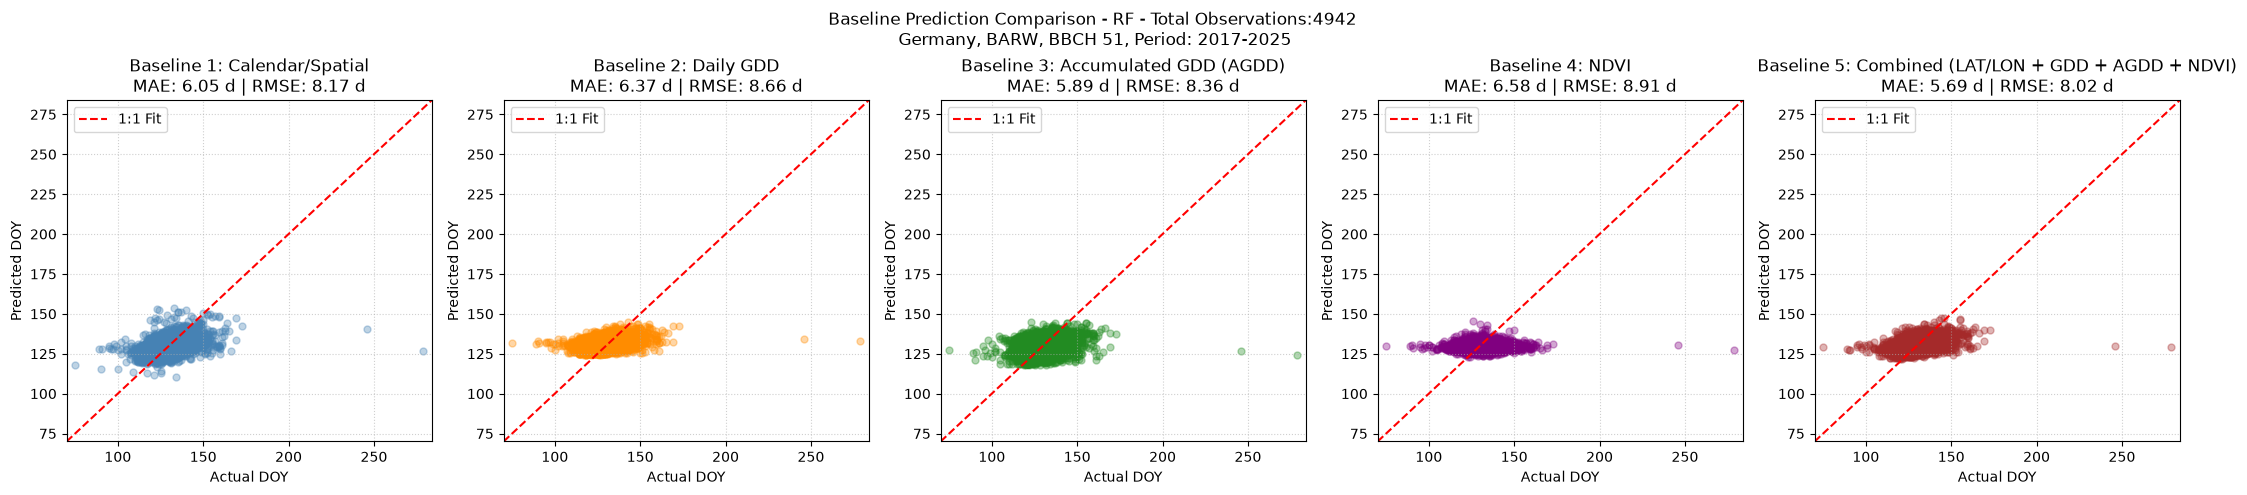

In [54]:
df_folds = pd.DataFrame(fold_results)

overall_b1_mae = mean_absolute_error(actual_doy, b1_predictions)
overall_b1_rmse = np.sqrt(mean_squared_error(actual_doy, b1_predictions))
overall_b2_mae = mean_absolute_error(actual_doy, b2_predictions)
overall_b2_rmse = np.sqrt(mean_squared_error(actual_doy, b2_predictions))
overall_b3_mae = mean_absolute_error(actual_doy, b3_predictions)
overall_b3_rmse = np.sqrt(mean_squared_error(actual_doy, b3_predictions))
overall_b4_mae = mean_absolute_error(actual_doy, b4_predictions)
overall_b4_rmse = np.sqrt(mean_squared_error(actual_doy, b4_predictions))
overall_b5_mae = mean_absolute_error(actual_doy, b5_predictions)
overall_b5_rmse = np.sqrt(mean_squared_error(actual_doy, b5_predictions))

# Print overall results
print(f"\n{'='*80}")
print(f"OVERALL LOYOCV BENCHMARK RESULTS (2017 onwards) ({selected_folder.name})")
print(f"{'='*80}")
print(f"Baseline 1: Calendar + Spatial (Year, Latitude, Longitude) --> Overall MAE:  {overall_b1_mae:.2f} days | Overall RMSE: {overall_b1_rmse:.2f} days")
print(f"Baseline 2: Daily GDD Profile (Latitude, Longitude + 365 Daily GDD Columns) --> Overall MAE:  {overall_b2_mae:.2f} days | Overall RMSE: {overall_b2_rmse:.2f} days")
print(f"Baseline 3: Accumulated GDD Profile (Latitude, Longitude + 365 AGDD Columns) --> Overall MAE:  {overall_b3_mae:.2f} days | Overall RMSE: {overall_b3_rmse:.2f} days")
print(f"Baseline 4: NDVI Profile (Latitude, Longitude + 365 Daily NDVI Columns) --> Overall MAE:  {overall_b4_mae:.2f} days | Overall RMSE: {overall_b4_rmse:.2f} days")
print(f"Baseline 5: Combined Daily GDD + Accumulated GDD + NDVI Profile (Latitude, Longitude + 365 Daily GDD + 365 Accumulated GDD + 365 Daily NDVI Columns) --> Overall MAE:  {overall_b5_mae:.2f} days | Overall RMSE: {overall_b5_rmse:.2f} days")

display(df_folds)

results_dir_baselines = Path("Results") / selected_folder.name / "LOYOCV_BASELINES"
results_dir_baselines.mkdir(parents=True, exist_ok=True)
results_path_filtered = results_dir_baselines / f"baselines_loyocv_results_rf.csv"
df_folds.to_csv(results_path_filtered, sep=";", index=False)

# Scatter plots for the 5 baselines 
plt.figure(figsize=(22, 5))

min_val = min(actual_doy) - 5
max_val = max(actual_doy) + 5

models_plot = [
    ("Baseline 1: Calendar/Spatial", b1_predictions, overall_b1_mae, overall_b1_rmse, "steelblue"),
    ("Baseline 2: Daily GDD", b2_predictions, overall_b2_mae, overall_b2_rmse, "darkorange"),
    ("Baseline 3: Accumulated GDD (AGDD)", b3_predictions, overall_b3_mae, overall_b3_rmse, "forestgreen"),
    ("Baseline 4: NDVI", b4_predictions, overall_b4_mae, overall_b4_rmse, "purple"),
    ("Baseline 5: Combined (LAT/LON + GDD + AGDD + NDVI)", b5_predictions, overall_b5_mae, overall_b5_rmse, "brown"),]

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot, 1):
    plt.subplot(1, 5, i)
    plt.scatter(actual_doy, predictions, alpha=0.35, color=color, s=25)
    plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=1.5, label="1:1 Fit")
    plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d")
    plt.xlabel("Actual DOY")
    plt.ylabel("Predicted DOY")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", frameon=True)
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)

plt.tight_layout()
plt.subplots_adjust(top=0.8)
plt.suptitle(f"Baseline Prediction Comparison - RF - Total Observations:{len(df_final)} \n{final_name}")
# Save plot
plt.savefig(results_dir_baselines / "scatter_comparison_baselines_rf", dpi=300, bbox_inches="tight")
plt.show()



### 2.4 $R^2$ Decomposition & Per-Year LOYOCV Trajectory Plots (Random Forest, Unreduced Features)

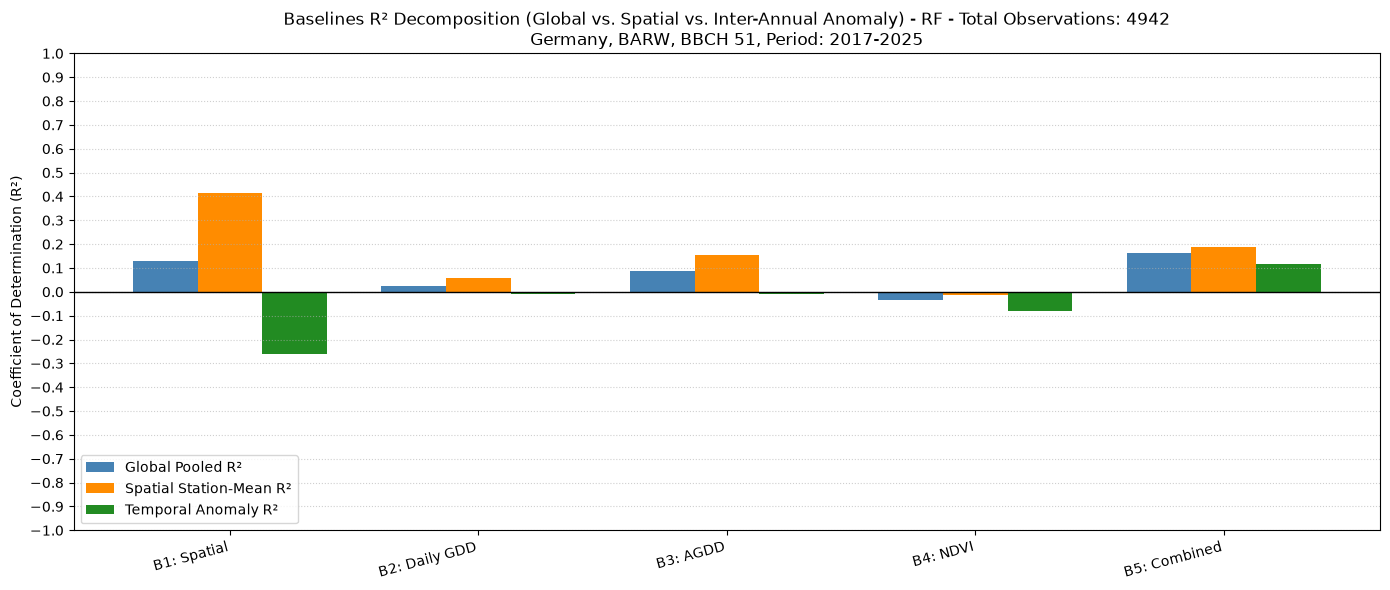

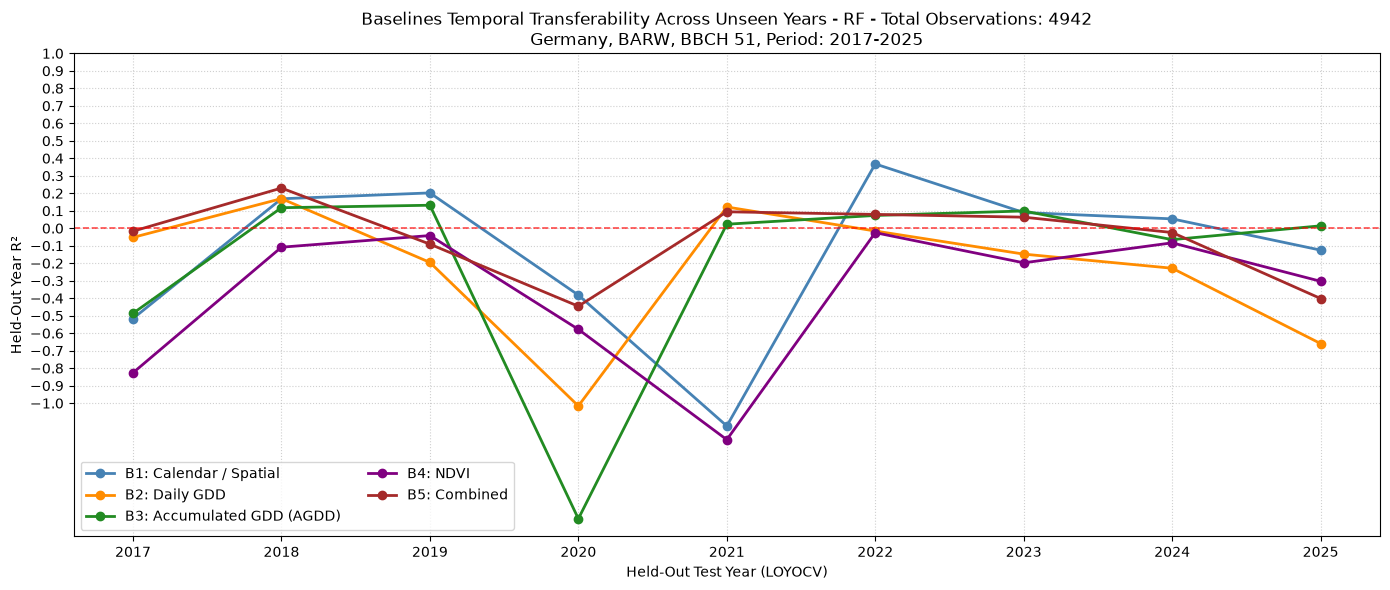

In [28]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array for boolean masking
actual_doy_arr = np.asarray(actual_doy)

# Build station identifier from df_final to separate spatial vs. temporal variance
if "PEP_ID" in df_final.columns:
    station_ids = df_final["PEP_ID"].values
else:
    station_ids = (
        df_final["Latitude"].round(4).astype(str)
        + "_"
        + df_final["Longitude"].round(4).astype(str)
    ).values

years_arr = df_final["Year"].astype(int).values

baseline_r2_models = [
    ("B1: Calendar / Spatial", np.asarray(b1_predictions), "steelblue"),
    ("B2: Daily GDD", np.asarray(b2_predictions), "darkorange"),
    ("B3: Accumulated GDD (AGDD)", np.asarray(b3_predictions), "forestgreen"),
    ("B4: NDVI", np.asarray(b4_predictions), "purple"),
    ("B5: Combined", np.asarray(b5_predictions), "brown"),
]

# R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R² (RF)
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    "B1: Spatial",
    "B2: Daily GDD",
    "B3: AGDD",
    "B4: NDVI",
    "B5: Combined",
]

for _, preds, _ in baseline_r2_models:
    # 1. Global Pooled R²
    g_r2 = r2_score(actual_doy_arr, preds)

    # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
    df_tmp = pd.DataFrame({
        "Station": station_ids,
        "Actual": actual_doy_arr,
        "Pred": preds,
    })
    st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
    s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

    df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
    obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
    pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
    t_r2 = r2_score(obs_anom, pred_anom)

    global_r2_list.append(g_r2)
    spatial_r2_list.append(s_r2)
    temporal_r2_list.append(t_r2)

# Save R² Decomposition values to CSV
df_r2_decomposition = pd.DataFrame({
    "Model_Key": [f"B{i}" for i in range(1, len(baseline_r2_models) + 1)],
    "Model_Label": short_labels,
    "Global_Pooled_R2": np.round(global_r2_list, 4),
    "Spatial_Station_Mean_R2": np.round(spatial_r2_list, 4),
    "Temporal_Anomaly_R2": np.round(temporal_r2_list, 4),
})
display(df_r2_decomposition)
df_r2_decomposition.to_csv(
    results_dir_baselines / "r2_decomposition_baselines_rf_unreduced.csv",
    sep=";",
    index=False,
)

x_pos = np.arange(len(baseline_r2_models))
bar_width = 0.26
y_ticks = np.arange(-1,1.1,step=0.1)

plt.figure(figsize=(14, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R²",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.yticks(y_ticks)
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"Baselines R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) - "
    f"RF - Total Observations: {len(df_final)}\n{final_name}"
)
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.savefig(
    results_dir_baselines / "r2_decomposition_baselines_rf_unreduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Per-Year LOYOCV R² Trajectory Across Held-Out Years (RF)
unique_years_plot = sorted(np.unique(years_arr))
df_r2_per_year = pd.DataFrame({"Test_Year": unique_years_plot})

plt.figure(figsize=(14, 6))

for idx, (m_label, preds, color) in enumerate(baseline_r2_models, start=1):
    yearly_r2 = []
    for yr in unique_years_plot:
        mask = years_arr == yr
        yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

    df_r2_per_year[f"B{idx}_R2"] = np.round(yearly_r2, 4)

    plt.plot(
        unique_years_plot,
        yearly_r2,
        marker="o",
        lw=2,
        color=color,
        label=m_label,
    )

# Save Per-Year R² values to CSV
display(df_r2_per_year)
df_r2_per_year.to_csv(
    results_dir_baselines / "r2_per_year_baselines_rf_unreduced.csv",
    sep=";",
    index=False,
)

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"Baselines Temporal Transferability Across Unseen Years - RF - "
    f"Total Observations: {len(df_final)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.xticks(unique_years_plot)
plt.yticks(y_ticks)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    results_dir_baselines / "r2_per_year_baselines_rf_unreduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### 2.5 LOYOCV Hyperparameter Search (XGBoost, Unreduced Features)

In [8]:
# Hyperparameter search space for Random Forest
print("=" * 80)
print("RUNNING LOYOCV HYPERPARAMETER SEARCH FOR BASELINES 1 TO 5 - XGBOOST")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_final[feat_cols]

    # Adapt feature subsampling ratio to feature space size
    if len(feat_cols) <= 3:
        colsample_dist = [1.0]
    else:
        colsample_dist = uniform(0.30, 0.50)  # Randomly samples between 30% and 80%

    xgb_param_distributions = {
        # Ensemble size and shrinkage
        "n_estimators": randint(150, 350),
        "learning_rate": uniform(0.02, 0.08),  # Range: 0.02 to 0.10
        # Tree architecture (keep shallow for small N)
        "max_depth": randint(3, 6),            # Depths 3, 4, 5
        "min_child_weight": randint(2, 7),     # Analogous to min_samples_leaf (2 to 6)
        "gamma": uniform(0.0, 1.5),            # Minimum loss reduction for a split
        # Stochastic sampling
        "subsample": uniform(0.65, 0.30),      # Row subsampling (0.65 to 0.95)
        "colsample_bytree": colsample_dist,    # Column subsampling
        # Regularization
        "reg_alpha": [0.0, 0.1, 1.0],
        "reg_lambda": [1.0, 3.0, 8.0],
    }

    xgb_search = RandomizedSearchCV(
        estimator=XGBRegressor(
            objective="reg:squarederror",
            eval_metric="mae",
            random_state=42,
            n_jobs=1,  # Keep inner booster single-threaded
        ),
        param_distributions=xgb_param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,  # Parallelize across CV folds/iterations
        verbose=0,
    )

    # Fit using groups to enforce Leave-One-Year-Out validation
    xgb_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = xgb_search.best_params_
    print(f" -> Best LOYOCV MAE: {-xgb_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {xgb_search.best_params_}")

# Create empty lists to append predictions and actual values for each baseline
b1_predictions = []
b2_predictions = []
b3_predictions = []
b4_predictions = []
b5_predictions = []

actual_doy = []
test_years_list = []
fold_results = []

print(f"\nBaseline 1 features ({len(features_b1)}): {features_b1}")
print(f"Baseline 2 features ({len(features_b2)}): 365 Daily GDD columns")
print(f"Baseline 3 features ({len(features_b3)}): 365 Accumulated GDD (AGDD) columns")
print(f"Baseline 4 features ({len(features_b4)}): 365 Daily NDVI columns")
print(f"Baseline 5 features ({len(features_b5)}): 365 Daily GDD + 365 Accumulated GDD (AGDD) + 365 Daily NDVI columns")

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR BASELINES 1 TO 5 - XGBOOST

Tuning B1 (Total Features: 2)...
 -> Best LOYOCV MAE: 6.08 days
 -> Optimal Parameters: {'colsample_bytree': 1.0, 'gamma': np.float64(0.3045918371021541), 'learning_rate': np.float64(0.09542828564463848), 'max_depth': 5, 'min_child_weight': 4, 'n_estimators': 235, 'reg_alpha': 0.1, 'reg_lambda': 3.0, 'subsample': np.float64(0.8924361138693251)}

Tuning B2 (Total Features: 365)...
 -> Best LOYOCV MAE: 6.44 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.5296244459829336), 'gamma': np.float64(0.5005629167085328), 'learning_rate': np.float64(0.031429345433755265), 'max_depth': 5, 'min_child_weight': 6, 'n_estimators': 151, 'reg_alpha': 0.1, 'reg_lambda': 3.0, 'subsample': np.float64(0.6502336297523044)}

Tuning B3 (Total Features: 365)...
 -> Best LOYOCV MAE: 5.81 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.4504391549083848), 'gamma': np.float64(0.4272607415662014), 'learning_rate': np.f

### 2.6 Run LOYOCV Evaluation (XGBoost, Unreduced Features)

In [9]:
print(f"Starting LOYOCV across {len(unique_years_filtered)} years (2017 onwards)...\n")

for test_year in unique_years_filtered:
    train_mask = df_final["Year"] != test_year
    test_mask = df_final["Year"] == test_year

    y_train = df_final.loc[train_mask, "DOY"]
    y_test = df_final.loc[test_mask, "DOY"]

# --- Baseline 1: Calendar & Spatial ---
    xgb_b1 = XGBRegressor(
        **best_params_dict["B1"], random_state=42, n_jobs=-1
    )
    xgb_b1.fit(
        df_final.loc[train_mask, features_b1], y_train
    )
    pred_b1 = xgb_b1.predict(
        df_final.loc[test_mask, features_b1]
    )

    # --- Baseline 2: Daily GDD ---
    xgb_b2 = XGBRegressor(
        **best_params_dict["B2"], random_state=42, n_jobs=-1
    )
    xgb_b2.fit(
        df_final.loc[train_mask, features_b2], y_train
    )
    pred_b2 = xgb_b2.predict(
        df_final.loc[test_mask, features_b2]
    )

    # --- Baseline 3: Accumulated GDD (AGDD) ---
    xgb_b3 = XGBRegressor(
        **best_params_dict["B3"], random_state=42, n_jobs=-1
    )
    xgb_b3.fit(
        df_final.loc[train_mask, features_b3], y_train
    )
    pred_b3 = xgb_b3.predict(
        df_final.loc[test_mask, features_b3]
    )

    # --- Baseline 4: NDVI ---
    xgb_b4 = XGBRegressor(
        **best_params_dict["B4"], random_state=42, n_jobs=-1
    )
    xgb_b4.fit(
        df_final.loc[train_mask, features_b4], y_train
    )
    pred_b4 = xgb_b4.predict(
        df_final.loc[test_mask, features_b4]
    )

    # --- Baseline 5: Combined Multimodal ---
    xgb_b5 = XGBRegressor(
        **best_params_dict["B5"], random_state=42, n_jobs=-1
    )
    xgb_b5.fit(
        df_final.loc[train_mask, features_b5], y_train
    )
    pred_b5 = xgb_b5.predict(
        df_final.loc[test_mask, features_b5]
    )


    # Fold metrics
    mae_b1 = mean_absolute_error(y_test, pred_b1)
    rmse_b1 = np.sqrt(mean_squared_error(y_test, pred_b1))

    mae_b2 = mean_absolute_error(y_test, pred_b2)
    rmse_b2 = np.sqrt(mean_squared_error(y_test, pred_b2))

    mae_b3 = mean_absolute_error(y_test, pred_b3)
    rmse_b3 = np.sqrt(mean_squared_error(y_test, pred_b3))

    mae_b4 = mean_absolute_error(y_test, pred_b4)
    rmse_b4 = np.sqrt(mean_squared_error(y_test, pred_b4))

    mae_b5 = mean_absolute_error(y_test, pred_b5)
    rmse_b5 = np.sqrt(mean_squared_error(y_test, pred_b5))

    fold_results.append(
        {
            "Test_Year": test_year,
            "N_Samples": len(y_test),
            "B1_Calendar_MAE": round(mae_b1, 2),
            "B1_Calendar_RMSE": round(rmse_b1, 2),
            "B2_DailyGDD_MAE": round(mae_b2, 2),
            "B2_DailyGDD_RMSE": round(rmse_b2, 2),
            "B3_AGDD_MAE": round(mae_b3, 2),
            "B3_AGDD_RMSE": round(rmse_b3, 2),
            "B4_NDVI_MAE": round(mae_b4, 2),
            "B4_NDVI_RMSE": round(rmse_b4, 2),
            "B5_Combined_MAE": round(mae_b5, 2),
            "B5_Combined_RMSE": round(rmse_b5, 2),
        }
    )

    b1_predictions.extend(pred_b1)
    b2_predictions.extend(pred_b2)
    b3_predictions.extend(pred_b3)
    b4_predictions.extend(pred_b4)
    b5_predictions.extend(pred_b5)
    actual_doy.extend(y_test.values)
    test_years_list.extend([test_year] * len(y_test))

    print(
        f"Year {test_year} (N={len(y_test):3d}) "
        f"B1 (Cal) MAE: {mae_b1:5.2f} d "
        f"B2 (GDD) MAE: {mae_b2:5.2f} d "
        f"B3 (AGDD) MAE: {mae_b3:5.2f} d "
        f"B4 (NDVI) MAE: {mae_b4:5.2f} d "
        f"B5 (Combined) MAE: {mae_b5:5.2f} d "
    )

print("\nLOYOCV evaluation finished!")


Starting LOYOCV across 9 years (2017 onwards)...

Year 2017 (N=621) B1 (Cal) MAE:  6.18 d B2 (GDD) MAE:  4.63 d B3 (AGDD) MAE:  5.75 d B4 (NDVI) MAE:  6.56 d B5 (Combined) MAE:  4.51 d 
Year 2018 (N=598) B1 (Cal) MAE:  4.33 d B2 (GDD) MAE:  4.29 d B3 (AGDD) MAE:  4.40 d B4 (NDVI) MAE:  5.21 d B5 (Combined) MAE:  4.06 d 
Year 2019 (N=592) B1 (Cal) MAE:  5.73 d B2 (GDD) MAE:  7.44 d B3 (AGDD) MAE:  5.80 d B4 (NDVI) MAE:  6.64 d B5 (Combined) MAE:  7.00 d 
Year 2020 (N=579) B1 (Cal) MAE:  6.90 d B2 (GDD) MAE:  8.50 d B3 (AGDD) MAE: 10.12 d B4 (NDVI) MAE:  7.21 d B5 (Combined) MAE:  6.97 d 
Year 2021 (N=543) B1 (Cal) MAE:  9.31 d B2 (GDD) MAE:  4.79 d B3 (AGDD) MAE:  5.11 d B4 (NDVI) MAE:  8.68 d B5 (Combined) MAE:  4.78 d 
Year 2022 (N=529) B1 (Cal) MAE:  3.55 d B2 (GDD) MAE:  4.90 d B3 (AGDD) MAE:  4.53 d B4 (NDVI) MAE:  4.65 d B5 (Combined) MAE:  4.51 d 
Year 2023 (N=511) B1 (Cal) MAE:  4.48 d B2 (GDD) MAE:  4.67 d B3 (AGDD) MAE:  4.16 d B4 (NDVI) MAE:  4.94 d B5 (Combined) MAE:  4.16 d

### 2.7 Summarize, Save & Scatter Plots (XGBoost, Unreduced Features)


OVERALL LOYOCV BENCHMARK RESULTS (2017 onwards) (germany_barw_bbch51_2017-01-01_2025-12-31)
Baseline 1: Calendar + Spatial (Year, Latitude, Longitude) --> Overall MAE:  6.05 days | Overall RMSE: 8.17 days
Baseline 2: Daily GDD Profile (Latitude, Longitude + 365 Daily GDD Columns) --> Overall MAE:  6.37 days | Overall RMSE: 8.66 days
Baseline 3: Accumulated GDD Profile (Latitude, Longitude + 365 AGDD Columns) --> Overall MAE:  5.89 days | Overall RMSE: 8.36 days
Baseline 4: NDVI Profile (Latitude, Longitude + 365 Daily NDVI Columns) --> Overall MAE:  6.58 days | Overall RMSE: 8.91 days
Baseline 5: Combined Daily GDD + Accumulated GDD + NDVI Profile (Latitude, Longitude + 365 Daily GDD + 365 Accumulated GDD + 365 Daily NDVI Columns) --> Overall MAE:  5.69 days | Overall RMSE: 8.02 days


,Test_Year,N_Samples,B1_Calendar_MAE,B1_Calendar_RMSE,B2_ReducedGDD_MAE,B2_ReducedGDD_RMSE,B3_ReducedAGDD_MAE,B3_ReducedAGDD_RMSE,B4_ReducedNDVI_MAE,B4_ReducedNDVI_RMSE,B5_ReducedCombined_MAE,B5_ReducedCombined_RMSE
0,2017,621,6.19,7.48,4.26,6.05,5.83,7.39,6.36,7.95,4.26,5.97
1,2018,598,4.31,5.85,4.80,6.43,4.19,5.79,5.13,6.76,5.23,6.87
2,2019,592,5.70,7.46,5.79,7.86,5.98,7.89,6.59,8.51,5.59,7.61
3,2020,579,6.92,8.32,5.18,6.90,6.61,8.16,7.35,9.01,5.28,6.92
4,2021,543,9.30,10.64,4.73,6.73,5.14,7.22,9.16,11.22,4.87,6.72
5,2022,529,3.54,5.05,4.43,6.05,4.42,6.08,4.59,6.45,4.38,5.96
6,2023,511,4.48,6.04,4.14,6.06,4.51,6.35,5.05,7.13,4.08,5.95
7,2024,488,6.48,11.49,5.64,11.60,6.02,12.06,7.17,12.18,5.76,11.78
8,2025,481,7.75,9.46,7.45,9.31,7.17,9.14,8.25,10.13,6.97,8.94


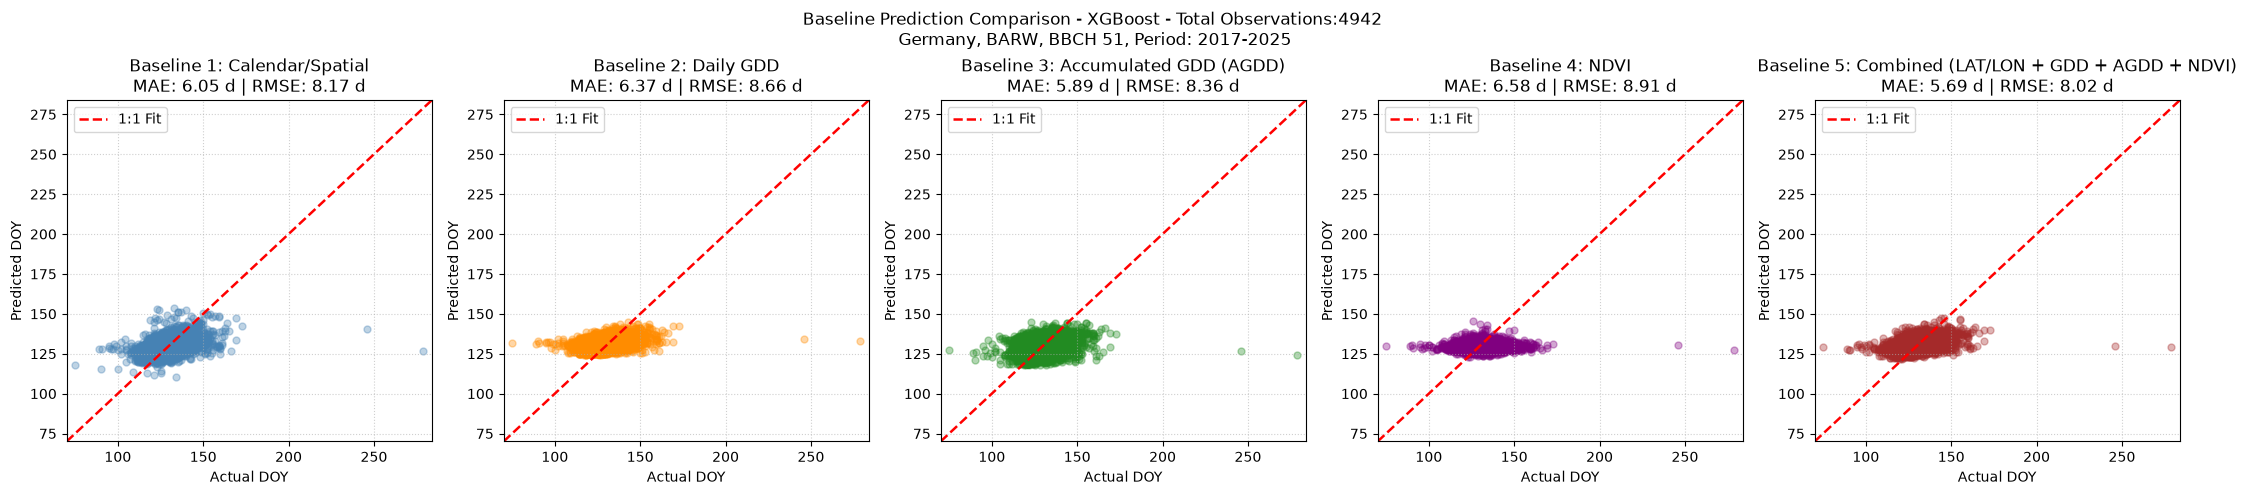

In [ ]:
# Save MAE and RMSE results
df_folds = pd.DataFrame(fold_results)

overall_b1_mae = mean_absolute_error(actual_doy, b1_predictions)
overall_b1_rmse = np.sqrt(mean_squared_error(actual_doy, b1_predictions))
overall_b2_mae = mean_absolute_error(actual_doy, b2_predictions)
overall_b2_rmse = np.sqrt(mean_squared_error(actual_doy, b2_predictions))
overall_b3_mae = mean_absolute_error(actual_doy, b3_predictions)
overall_b3_rmse = np.sqrt(mean_squared_error(actual_doy, b3_predictions))
overall_b4_mae = mean_absolute_error(actual_doy, b4_predictions)
overall_b4_rmse = np.sqrt(mean_squared_error(actual_doy, b4_predictions))
overall_b5_mae = mean_absolute_error(actual_doy, b5_predictions)
overall_b5_rmse = np.sqrt(mean_squared_error(actual_doy, b5_predictions))

# Print overall results
print(f"\n{'='*80}")
print(f"OVERALL LOYOCV BENCHMARK RESULTS (2017 onwards) ({selected_folder.name})")
print(f"{'='*80}")
print(f"Baseline 1: Calendar + Spatial (Year, Latitude, Longitude) --> Overall MAE:  {overall_b1_mae:.2f} days | Overall RMSE: {overall_b1_rmse:.2f} days")
print(f"Baseline 2: Daily GDD Profile (Latitude, Longitude + 365 Daily GDD Columns) --> Overall MAE:  {overall_b2_mae:.2f} days | Overall RMSE: {overall_b2_rmse:.2f} days")
print(f"Baseline 3: Accumulated GDD Profile (Latitude, Longitude + 365 AGDD Columns) --> Overall MAE:  {overall_b3_mae:.2f} days | Overall RMSE: {overall_b3_rmse:.2f} days")
print(f"Baseline 4: NDVI Profile (Latitude, Longitude + 365 Daily NDVI Columns) --> Overall MAE:  {overall_b4_mae:.2f} days | Overall RMSE: {overall_b4_rmse:.2f} days")
print(f"Baseline 5: Combined Daily GDD + Accumulated GDD + NDVI Profile (Latitude, Longitude + 365 Daily GDD + 365 Accumulated GDD + 365 Daily NDVI Columns) --> Overall MAE:  {overall_b5_mae:.2f} days | Overall RMSE: {overall_b5_rmse:.2f} days")

display(df_folds)

results_path_filtered = results_dir_baselines / f"baselines_loyocv_results_xgboost.csv"
df_folds.to_csv(results_path_filtered, sep=";", index=False)

# Scatter plots for the 5 baselines 
plt.figure(figsize=(22, 5))

models_plot = [
    ("Baseline 1: Calendar/Spatial", b1_predictions, overall_b1_mae, overall_b1_rmse, "steelblue"),
    ("Baseline 2: Daily GDD", b2_predictions, overall_b2_mae, overall_b2_rmse, "darkorange"),
    ("Baseline 3: Accumulated GDD (AGDD)", b3_predictions, overall_b3_mae, overall_b3_rmse, "forestgreen"),
    ("Baseline 4: NDVI", b4_predictions, overall_b4_mae, overall_b4_rmse, "purple"),
    ("Baseline 5: Combined (LAT/LON + GDD + AGDD + NDVI)", b5_predictions, overall_b5_mae, overall_b5_rmse, "brown"),]

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot, 1):
    plt.subplot(1, 5, i)
    plt.scatter(actual_doy, predictions, alpha=0.35, color=color, s=25)
    plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=1.8, label="1:1 Fit")
    plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d")
    plt.xlabel("Actual DOY")
    plt.ylabel("Predicted DOY")
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", frameon=True)
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)

plt.tight_layout()
plt.subplots_adjust(top=0.8)
plt.suptitle(f"Baseline Prediction Comparison - XGBoost - Total Observations:{len(df_final)} \n{final_name}")
# Save plot
plt.savefig(results_dir_baselines / "scatter_comparison_baselines_xgboost", dpi=300, bbox_inches="tight")
plt.show()

### 2.8 $R^2$ Decomposition & Per-Year LOYOCV Trajectory Plots (XGBoost, Unreduced Features)

,Model_Key,Model_Label,Global_Pooled_R2,Spatial_Station_Mean_R2,Temporal_Anomaly_R2
0,B1,B1: Spatial,0.1308,0.4147,-0.2599
1,B2,B2: Daily GDD,0.0231,0.0568,-0.0089
2,B3,B3: AGDD,0.0883,0.1546,-0.0108
3,B4,B4: NDVI,-0.0340,-0.0130,-0.0790
4,B5,B5: Combined,0.1615,0.1874,0.1160


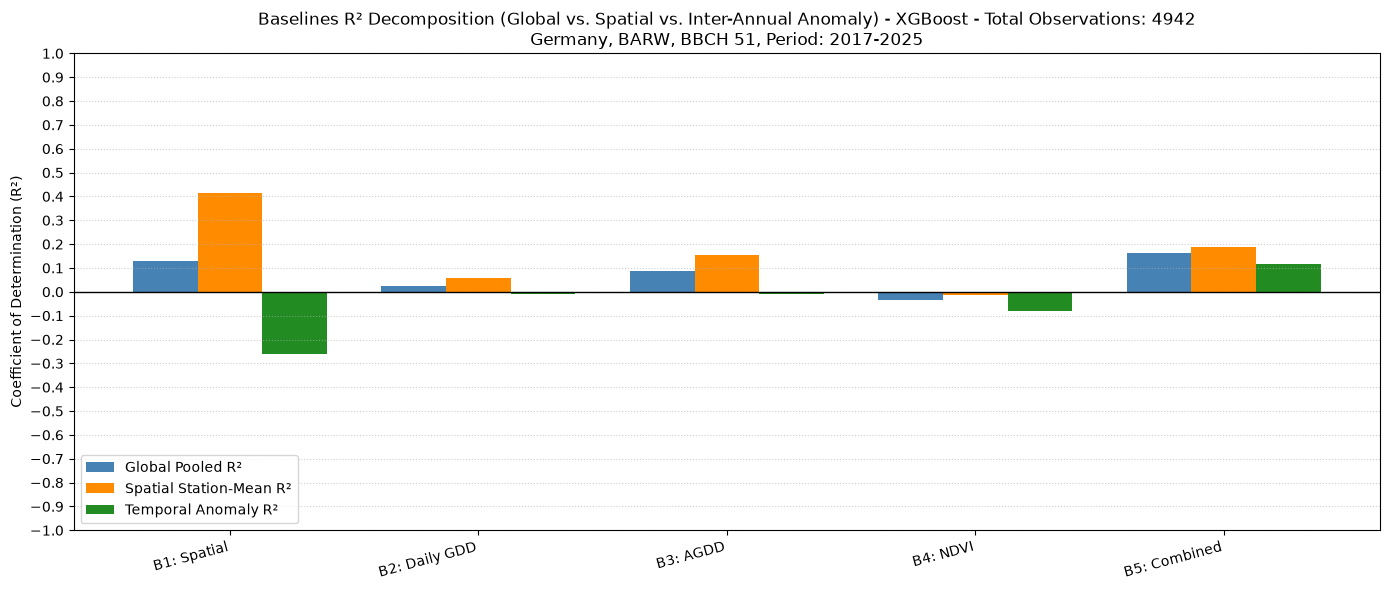

,Test_Year,B1_R2,B2_R2,B3_R2,B4_R2,B5_R2
0,2017,-0.5163,-0.0524,-0.4863,-0.8262,-0.0169
1,2018,0.1685,0.1695,0.1175,-0.1083,0.2299
2,2019,0.2021,-0.1952,0.1316,-0.0417,-0.0908
3,2020,-0.3820,-1.0160,-1.6608,-0.5779,-0.4457
4,2021,-1.1304,0.1216,0.0231,-1.2087,0.0942
5,2022,0.3677,-0.0158,0.0732,-0.0252,0.0792
6,2023,0.0900,-0.1478,0.0989,-0.1976,0.0633
7,2024,0.0537,-0.2286,-0.0651,-0.0833,-0.0243
8,2025,-0.1250,-0.6593,0.0140,-0.3032,-0.4017


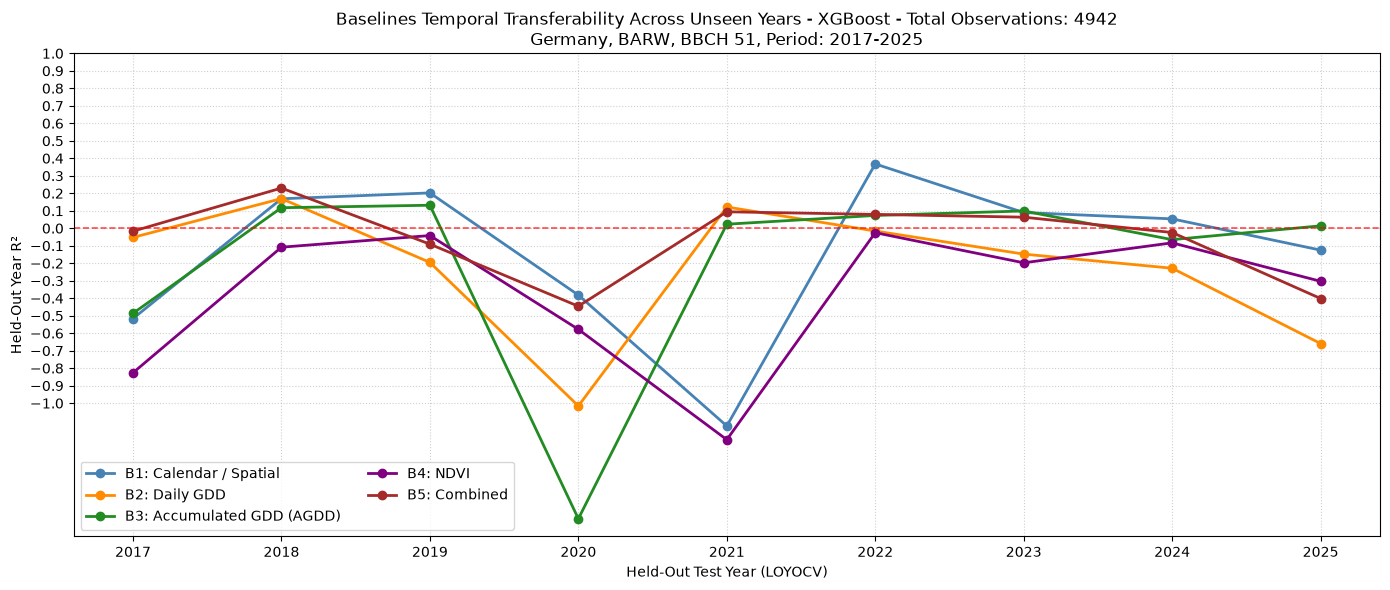

In [73]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array for boolean masking
actual_doy_arr = np.asarray(actual_doy)

# Build station identifier from df_final to separate spatial vs. temporal variance
if "PEP_ID" in df_final.columns:
    station_ids = df_final["PEP_ID"].values
else:
    station_ids = (
        df_final["Latitude"].round(4).astype(str)
        + "_"
        + df_final["Longitude"].round(4).astype(str)
    ).values

years_arr = df_final["Year"].astype(int).values

baseline_r2_models = [
    ("B1: Calendar / Spatial", np.asarray(b1_predictions), "steelblue"),
    ("B2: Daily GDD", np.asarray(b2_predictions), "darkorange"),
    ("B3: Accumulated GDD (AGDD)", np.asarray(b3_predictions), "forestgreen"),
    ("B4: NDVI", np.asarray(b4_predictions), "purple"),
    ("B5: Combined", np.asarray(b5_predictions), "brown"),
]

# R² Decomposition Plot & DataFrame 1 (Global vs. Spatial vs. Temporal)
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    "B1: Spatial",
    "B2: Daily GDD",
    "B3: AGDD",
    "B4: NDVI",
    "B5: Combined",
]

for _, preds, _ in baseline_r2_models:
    # 1. Global Pooled R²
    g_r2 = r2_score(actual_doy_arr, preds)

    # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
    df_tmp = pd.DataFrame({
        "Station": station_ids,
        "Actual": actual_doy_arr,
        "Pred": preds,
    })
    st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
    s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

    df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
    obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
    pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
    t_r2 = r2_score(obs_anom, pred_anom)

    global_r2_list.append(g_r2)
    spatial_r2_list.append(s_r2)
    temporal_r2_list.append(t_r2)

# DataFrame 1: Values used in Plot 1 (R² Decomposition)
df_r2_decomposition = pd.DataFrame({
    "Model_Key": [f"B{i}" for i in range(1, len(baseline_r2_models) + 1)],
    "Model_Label": short_labels,
    "Global_Pooled_R2": np.round(global_r2_list, 4),
    "Spatial_Station_Mean_R2": np.round(spatial_r2_list, 4),
    "Temporal_Anomaly_R2": np.round(temporal_r2_list, 4),
})
display(df_r2_decomposition)
df_r2_decomposition.to_csv(
    results_dir_baselines / "r2_decomposition_baselines_xgboost_unreduced.csv",
    sep=";",
    index=False,
)

x_pos = np.arange(len(baseline_r2_models))
bar_width = 0.26

plt.figure(figsize=(14, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R²",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.yticks(y_ticks)
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"Baselines R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) - "
    f"XGBoost - Total Observations: {len(df_final)}\n{final_name}"
)
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.savefig(
    results_dir_baselines / "r2_decomposition_baselines_xgboost_unreduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Per-Year LOYOCV R² Trajectory Plot & DataFrame 2
unique_years_plot = sorted(np.unique(years_arr))

# DataFrame 2: Values used in Plot 2 (Per-Year R² for B1–B5)
df_r2_per_year = pd.DataFrame({"Test_Year": unique_years_plot})

plt.figure(figsize=(14, 6))

for idx, (m_label, preds, color) in enumerate(baseline_r2_models, start=1):
    yearly_r2 = []
    for yr in unique_years_plot:
        mask = years_arr == yr
        yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

    df_r2_per_year[f"B{idx}_R2"] = np.round(yearly_r2, 4)

    plt.plot(
        unique_years_plot,
        yearly_r2,
        marker="o",
        lw=2,
        color=color,
        label=m_label,
    )

display(df_r2_per_year)
df_r2_per_year.to_csv(
    results_dir_baselines / "r2_per_year_baselines_xgboost_unreduced.csv",
    sep=";",
    index=False,
)

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"Baselines Temporal Transferability Across Unseen Years - XGBoost - "
    f"Total Observations: {len(df_final)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.xticks(unique_years_plot)
plt.yticks(y_ticks)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    results_dir_baselines / "r2_per_year_baselines_xgboost_unreduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Part 3: Domain-Reduced Baseline Features (1,097 -> 78 Features)
### 3.1 Initialize Reduced DataFrame

In [12]:
# dataframe to use 
df_reduced = pd.DataFrame()

# Get the basic columns of the df_final
df_reduced["Year"] = df_final["Year"].astype(int)
df_reduced["Latitude"] = df_final["Latitude"]
df_reduced["Longitude"] = df_final["Longitude"]
df_reduced["DOY"] = df_final["DOY"]

### 3.2 Feature Reduction for Daily GDD (12 Monthly Sums + Chilling & Heat Stress)

In [13]:
# We compress 365 noisy daily columns into 12 monthly thermal integrals that
# represent discrete developmental phases (winter dormancy, spring resumption,
# summer maturation, and autumn harvest), plus chilling and heat-stress indicators.
gdd_cols = [c for c in df_final.columns if c.startswith("GDD_doy_")]
if gdd_cols:
    gdd_mat = df_final[gdd_cols].values  # Shape: (N, 365)

    # 1.1 Monthly Thermal Integrals (January to December)
    # Each slice sums the thermal energy accrued specifically within that 30/31-day calendar block.
    # Jan (1-31), Feb (32-59), Mar (60-90), Apr (91-120), May (121-151), Jun (152-181),
    # Jul (182-212), Aug (213-243), Sep (244-273), Oct (274-304), Nov (305-334), Dec (335-365).
    month_slices = {
        "Jan": (0, 31),
        "Feb": (31, 59),
        "Mar": (59, 90),
        "Apr": (90, 120),
        "May": (120, 151),
        "Jun": (151, 181),
        "Jul": (181, 212),
        "Aug": (212, 243),
        "Sep": (243, 273),
        "Oct": (273, 304),
        "Nov": (304, 334),
        "Dec": (334, 365),
    }

    for month_name, (start_idx, end_idx) in month_slices.items():
        # Captures monthly heat velocity without forcing the tree to learn cross-column additions
        df_reduced[f"GDD_sum_{month_name}"] = gdd_mat[:, start_idx:end_idx].sum(axis=1)

    # 1.2 Dormancy Pause / Cold Delay Days (DOY 1 to 120: Jan 1 - Apr 30)
    # Counts days where GDD <= 0.5°C (mean temp <= base temp), directly capturing
    # winter chilling severity and early-season developmental stalls.
    df_reduced["GDD_cold_days_winter_spring"] = (gdd_mat[:, 0:120] <= 0.5).sum(axis=1)

    # 1.3 Summer Heat Concentration (DOY 152 to 243: Jun 1 - Aug 31)
    # Measures the magnitude of peak summer thermal forcing during grain/tuber filling.
    df_reduced["GDD_sum_summer_peak"] = gdd_mat[:, 151:243].sum(axis=1)

### 3.3 Feature Reduction for Accumulated GDD (28 Bi-Weekly Checkpoints)

In [14]:
# Sampling at a fixed 7-day cadence across the entire 365-day year eliminates 93%
# of collinear columns while capturing total heat accumulation from planting to harvest.

agdd_checkpoints_doy = [
    7, 14, 21, 28, 42, 56, 70, 84, 98, 112, 126, 140, 154, 168, 182,
    196, 210, 224, 238, 252, 266, 280, 294, 308, 322, 336, 350, 365
]

for doy_val in agdd_checkpoints_doy:
    col_name = f"AGDD_doy_{doy_val}"
    if col_name in df_final.columns:
        df_reduced[col_name] = df_final[col_name]

### 3.4 Feature Reduction for Daily NDVI (6 LSP Curve Metrics + 28 Bi-Weekly ANDVI Checkpoints)

In [15]:
# We extract: (a) 5 core Land Surface Phenology (LSP) curve parameters, and
# (b) 26 bi-weekly Accumulated NDVI (ANDVI) checkpoints representing cumulative biomass.
ndvi_cols = [c for c in df_final.columns if c.startswith("NDVI_doy_")]
if ndvi_cols:
    ndvi_mat = df_final[ndvi_cols].values  # Shape: (N, 365)

    # 3.1 Winter/Soil Baseline Reflectance (DOY 1 to 75)
    # Captures un-vegetated background soil and residue reflectance
    df_reduced["NDVI_base"] = np.min(ndvi_mat[:, 0:75], axis=1)

    # 3.2 Peak Canopy Value and Timing (DOY 60 to 300)
    # The day of maximum NDVI is the primary optical anchor for heading, flowering, and peak biomass
    ndvi_growth_window = ndvi_mat[:, 59:300]
    df_reduced["NDVI_max"] = np.max(ndvi_growth_window, axis=1)
    df_reduced["NDVI_peak_doy"] = np.argmax(ndvi_growth_window, axis=1) + 60

    # 3.3 Seasonal Canopy Amplitude
    # Difference between maximum green canopy and bare ground (total seasonal leaf capacity)
    df_reduced["NDVI_amplitude"] = df_reduced["NDVI_max"] - df_reduced["NDVI_base"]

    # 3.4 Maximum Green-up Velocity (Slope)
    # The maximum 7-day rate of change during the spring green-up surge
    ndvi_7d_diff = ndvi_growth_window[:, 7:] - ndvi_growth_window[:, :-7]
    df_reduced["NDVI_max_greenup_slope"] = np.max(ndvi_7d_diff, axis=1) / 7.0

    # 3.5 Total Integrated Seasonal Vigor (AUC)
    # Integral of NDVI exceeding background soil reflectance (proxy for total absorbed radiation)
    df_reduced["NDVI_AUC_seasonal"] = np.sum(np.clip(ndvi_mat - 0.20, 0, None), axis=1)

    # 3.6 Accumulated NDVI (ANDVI) Across the Full Year (26 Bi-Weekly Checkpoints)
    # We integrate daily active canopy cover (excess over soil threshold 0.15)
    # and sample cumulative intercepted radiation at the exact same 14-day intervals as AGDD.
    andvi_daily_integral = np.cumsum(np.clip(ndvi_mat - 0.15, 0, None), axis=1)
    for doy_val in agdd_checkpoints_doy:
        # ANDVI acts as the cumulative biomass odometer for the tree models
        df_reduced[f"ANDVI_biweekly_doy_{doy_val}"] = andvi_daily_integral[:, doy_val - 1]

### 3.5 Define Reduced Baseline Sets & Run LOYOCV Hyperparameter Search (Random Forest)

In [16]:
# 4. Create the different featur sets for the baselines 
features_b1 = ["Latitude", "Longitude"]

features_b2 = [
    c for c in df_reduced.columns if c.startswith("GDD_")
]

features_b3 = [
    c for c in df_reduced.columns if c.startswith("AGDD_")
]

features_b4 = [
    c for c in df_reduced.columns if c.startswith("NDVI_") or c.startswith("ANDVI_")
]

features_b5 = (
    ["Latitude", "Longitude"]
    + [c for c in df_reduced.columns if c.startswith("GDD_")]
    + [c for c in df_reduced.columns if c.startswith("AGDD_")]
    + [c for c in df_reduced.columns if c.startswith("NDVI_") or c.startswith("ANDVI_")]
)

# Set up dictionary for the baseline feature sets
models_to_tune = {
    "B1": features_b1,
    "B2": features_b2,
    "B3": features_b3,
    "B4": features_b4,
    "B5": features_b5,
}

y_all = df_reduced["DOY"]
groups_all = df_reduced["Year"]
logo = LeaveOneGroupOut()

best_params_dict = {}

# 2. HYPERPARAMETER SEARCH ACROSS EACH BASELINE
print("=" * 80)
print("RUNNING LOYOCV HYPERPARAMETER SEARCH FOR BASELINES 1 TO 5 - RF")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_reduced[feat_cols]

    # Adjust max_features distribution based on feature count
    if len(feat_cols) <= 3:
        max_feat_dist = [1.0]
    else:
        max_feat_dist = uniform(0.25, 0.50)  # samples between 25% and 75% of features

    param_distributions = {
        "n_estimators": randint(150, 350),
        "max_depth": [None, 12, 18, 25],
        "min_samples_leaf": randint(1, 5),
        "min_samples_split": randint(2, 6),
        "max_features": max_feat_dist,
    }

    rf_search = RandomizedSearchCV(
        estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
        param_distributions=param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,
        verbose=0,
    )

    rf_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = rf_search.best_params_
    print(f" -> Best LOYOCV MAE: {-rf_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {rf_search.best_params_}")

print("=" * 75)
print("FEATURE REDUCTION SUMMARY (FULL-YEAR CALENDAR)")
print("=" * 75)
print(f"Total Observation Records:               {len(df_reduced)}")
print(f"Baseline 1 (Calendar & Spatial):         {len(features_b1):3d} features")
print(f"Baseline 2 (GDD - 12 Months + Stress):   {len(features_b2):3d} features")
print(f"Baseline 3 (AGDD - 26 Bi-Weekly Steps):  {len(features_b3):3d} features")
print(f"Baseline 4 (NDVI - LSP Metrics + ANDVI): {len(features_b4):3d} features")
print(f"Baseline 5 (Combined Multimodal B1-B4):  {len(features_b5):3d} features")
print("=" * 75)

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR BASELINES 1 TO 5 - RF

Tuning B1 (Total Features: 2)...
 -> Best LOYOCV MAE: 6.05 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 3, 'n_estimators': 233}

Tuning B2 (Total Features: 14)...
 -> Best LOYOCV MAE: 5.22 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': np.float64(0.25038938292050716), 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 310}

Tuning B3 (Total Features: 28)...
 -> Best LOYOCV MAE: 5.48 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': np.float64(0.7244427686266666), 'min_samples_leaf': 4, 'min_samples_split': 3, 'n_estimators': 158}

Tuning B4 (Total Features: 34)...
 -> Best LOYOCV MAE: 6.64 days
 -> Optimal Parameters: {'max_depth': 12, 'max_features': np.float64(0.25038938292050716), 'min_samples_leaf': 4, 'min_samples_split': 2, 'n_estimators': 310}

Tuning B5 (Total Features: 78)...
 -> Best LOYOCV MAE: 5.16 days
 

### 3.6 Run LOYOCV Evaluation & Summarize Reduced Baseline Results (Random Forest)

In [17]:
# 5. EXECUTE LEAVE-ONE-YEAR-OUT CROSS-VALIDATION (LOYOCV) ON REDUCED BASELINES
unique_years = sorted(df_reduced["Year"].unique())

b1_preds, b2_preds, b3_preds, b4_preds, b5_preds = [], [], [], [], []
actual_doy = []
test_years_list = []
fold_results = []

print(f"\nStarting LOYOCV across {len(unique_years)} annual folds...\n")

for test_year in unique_years:
    train_mask = df_reduced["Year"] != test_year
    test_mask = df_reduced["Year"] == test_year

    y_train = df_reduced.loc[train_mask, "DOY"]
    y_test = df_reduced.loc[test_mask, "DOY"]

    # Model definition: trees can now split cleanly without noise dilution

    # Fit B1
    rf_b1 = RandomForestRegressor(**best_params_dict["B1"], random_state=42, n_jobs=-1)
    rf_b1.fit(df_reduced.loc[train_mask, features_b1], y_train)
    pred_b1 = rf_b1.predict(df_reduced.loc[test_mask, features_b1])

    # Fit B2
    rf_b2 = RandomForestRegressor(**best_params_dict["B2"], random_state=42, n_jobs=-1)
    rf_b2.fit(df_reduced.loc[train_mask, features_b2], y_train)
    pred_b2 = rf_b2.predict(df_reduced.loc[test_mask, features_b2])

    # Fit B3
    rf_b3 = RandomForestRegressor(**best_params_dict["B3"], random_state=42, n_jobs=-1)
    rf_b3.fit(df_reduced.loc[train_mask, features_b3], y_train)
    pred_b3 = rf_b3.predict(df_reduced.loc[test_mask, features_b3])

    # Fit B4
    rf_b4 = RandomForestRegressor(**best_params_dict["B4"], random_state=42, n_jobs=-1)
    rf_b4.fit(df_reduced.loc[train_mask, features_b4], y_train)
    pred_b4 = rf_b4.predict(df_reduced.loc[test_mask, features_b4])

    # Fit B5
    rf_b5 = RandomForestRegressor(**best_params_dict["B5"], random_state=42, n_jobs=-1)
    rf_b5.fit(df_reduced.loc[train_mask, features_b5], y_train)
    pred_b5 = rf_b5.predict(df_reduced.loc[test_mask, features_b5])

    # Compute fold-level MAE
    mae_b1 = mean_absolute_error(y_test, pred_b1)
    mae_b2 = mean_absolute_error(y_test, pred_b2)
    mae_b3 = mean_absolute_error(y_test, pred_b3)
    mae_b4 = mean_absolute_error(y_test, pred_b4)
    mae_b5 = mean_absolute_error(y_test, pred_b5)

    # Compute fold-level RMSE
    rmse_b1 = np.sqrt(mean_squared_error(y_test, pred_b1))
    rmse_b2 = np.sqrt(mean_squared_error(y_test, pred_b2))
    rmse_b3 = np.sqrt(mean_squared_error(y_test, pred_b3))
    rmse_b4 = np.sqrt(mean_squared_error(y_test, pred_b4))
    rmse_b5 = np.sqrt(mean_squared_error(y_test, pred_b5))

    fold_results.append({
        "Test_Year": test_year,
        "N_Samples": len(y_test),
        "B1_Calendar_MAE": round(mae_b1, 2),
        "B1_Calendar_RMSE": round(rmse_b1, 2),
        "B2_ReducedGDD_MAE": round(mae_b2, 2),
        "B2_ReducedGDD_RMSE": round(rmse_b2, 2),
        "B3_ReducedAGDD_MAE": round(mae_b3, 2),
        "B3_ReducedAGDD_RMSE": round(rmse_b3, 2),
        "B4_ReducedNDVI_MAE": round(mae_b4, 2),
        "B4_ReducedNDVI_RMSE": round(rmse_b4, 2),
        "B5_ReducedCombined_MAE": round(mae_b5, 2),
        "B5_ReducedCombined_RMSE": round(rmse_b5, 2),
    })

    b1_preds.extend(pred_b1)
    b2_preds.extend(pred_b2)
    b3_preds.extend(pred_b3)
    b4_preds.extend(pred_b4)
    b5_preds.extend(pred_b5)
    actual_doy.extend(y_test.values)
    test_years_list.extend([test_year] * len(y_test))

    print(
        f"Year {test_year} (N={len(y_test):3d}) | "
        f"B1: {mae_b1:5.2f}d | B2: {mae_b2:5.2f}d | "
        f"B3: {mae_b3:5.2f}d | B4: {mae_b4:5.2f}d | B5: {mae_b5:5.2f}d"
    )

print("\nLOYOCV execution finished!")

# 6. POOLED METRICS AND SUMMARY EXPORT
df_folds_reduced = pd.DataFrame(fold_results)

# Micro-averaged pooled metrics across all held-out sample years
overall_b1_mae = mean_absolute_error(actual_doy, b1_preds)
overall_b1_rmse = np.sqrt(mean_squared_error(actual_doy, b1_preds))

overall_b2_mae = mean_absolute_error(actual_doy, b2_preds)
overall_b2_rmse = np.sqrt(mean_squared_error(actual_doy, b2_preds))

overall_b3_mae = mean_absolute_error(actual_doy, b3_preds)
overall_b3_rmse = np.sqrt(mean_squared_error(actual_doy, b3_preds))

overall_b4_mae = mean_absolute_error(actual_doy, b4_preds)
overall_b4_rmse = np.sqrt(mean_squared_error(actual_doy, b4_preds))

overall_b5_mae = mean_absolute_error(actual_doy, b5_preds)
overall_b5_rmse = np.sqrt(mean_squared_error(actual_doy, b5_preds))

print("=" * 85)
print("POOLED LOYOCV RESULTS: REDUCED BASELINE HIERARCHY")
print("=" * 85)
print(f"Baseline 1 (Calendar & Spatial):         MAE: {overall_b1_mae:5.2f} d | RMSE: {overall_b1_rmse:5.2f} d")
print(f"Baseline 2 (Reduced 12M GDD + Stress):   MAE: {overall_b2_mae:5.2f} d | RMSE: {overall_b2_rmse:5.2f} d")
print(f"Baseline 3 (Reduced 26-Step AGDD):       MAE: {overall_b3_mae:5.2f} d | RMSE: {overall_b3_rmse:5.2f} d")
print(f"Baseline 4 (Reduced NDVI LSP + ANDVI):   MAE: {overall_b4_mae:5.2f} d | RMSE: {overall_b4_rmse:5.2f} d")
print(f"Baseline 5 (Reduced Combined Multimodal):MAE: {overall_b5_mae:5.2f} d | RMSE: {overall_b5_rmse:5.2f} d")
print("-" * 85)
print(f"Difference B5 vs B1 (Combined vs Spatial): {overall_b5_mae - overall_b1_mae:+5.2f} d MAE")
print("=" * 85)

display(df_folds_reduced)

# 7. SAVE RESULTS
summary_path = results_dir_baselines / "baselines_loyocv_results_rf_reduced.csv"
df_folds_reduced.to_csv(summary_path, sep=";", index=False)
print(f"\nSaved fold summary to: {summary_path.resolve()}")


Starting LOYOCV across 9 annual folds...

Year 2017 (N=621) | B1:  6.20d | B2:  4.08d | B3:  5.02d | B4:  6.33d | B5:  4.00d
Year 2018 (N=598) | B1:  4.22d | B2:  4.62d | B3:  4.27d | B4:  5.15d | B5:  4.97d
Year 2019 (N=592) | B1:  5.64d | B2:  5.80d | B3:  6.16d | B4:  6.57d | B5:  5.71d
Year 2020 (N=579) | B1:  6.88d | B2:  5.52d | B3:  6.76d | B4:  7.34d | B5:  5.45d
Year 2021 (N=543) | B1:  9.35d | B2:  4.87d | B3:  4.76d | B4:  9.10d | B5:  4.61d
Year 2022 (N=529) | B1:  3.51d | B2:  4.29d | B3:  4.63d | B4:  4.63d | B5:  4.38d
Year 2023 (N=511) | B1:  4.51d | B2:  4.02d | B3:  4.63d | B4:  5.17d | B5:  4.02d
Year 2024 (N=488) | B1:  6.48d | B2:  5.62d | B3:  6.69d | B4:  7.15d | B5:  5.98d
Year 2025 (N=481) | B1:  7.70d | B2:  8.13d | B3:  6.39d | B4:  8.30d | B5:  7.30d

LOYOCV execution finished!
POOLED LOYOCV RESULTS: REDUCED BASELINE HIERARCHY
Baseline 1 (Calendar & Spatial):         MAE:  6.03 d | RMSE:  8.16 d
Baseline 2 (Reduced 12M GDD + Stress):   MAE:  5.17 d | RMSE: 

,Test_Year,N_Samples,B1_Calendar_MAE,B1_Calendar_RMSE,B2_ReducedGDD_MAE,B2_ReducedGDD_RMSE,B3_ReducedAGDD_MAE,B3_ReducedAGDD_RMSE,B4_ReducedNDVI_MAE,B4_ReducedNDVI_RMSE,B5_ReducedCombined_MAE,B5_ReducedCombined_RMSE
0,2017,621,6.20,7.45,4.08,5.71,5.02,6.71,6.33,7.97,4.00,5.68
1,2018,598,4.22,5.80,4.62,6.26,4.27,5.85,5.15,6.83,4.97,6.57
2,2019,592,5.64,7.43,5.80,7.84,6.16,8.03,6.57,8.51,5.71,7.68
3,2020,579,6.88,8.30,5.52,7.10,6.76,8.30,7.34,9.02,5.45,7.09
4,2021,543,9.35,10.67,4.87,6.85,4.76,6.76,9.10,11.19,4.61,6.49
5,2022,529,3.51,5.05,4.29,6.00,4.63,6.25,4.63,6.44,4.38,5.98
6,2023,511,4.51,6.08,4.02,5.87,4.63,6.44,5.17,7.22,4.02,5.78
7,2024,488,6.48,11.53,5.62,11.57,6.69,12.57,7.15,12.22,5.98,11.93
8,2025,481,7.70,9.43,8.13,9.87,6.39,8.72,8.30,10.20,7.30,9.19



Saved fold summary to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_BASELINES\baselines_loyocv_results_rf_reduced.csv


### 3.7 Scatter Plots (Random Forest, Reduced Features)

Scatter plot matrix saved to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_BASELINES\scatter_comparison_baselines_rf_reduced.png


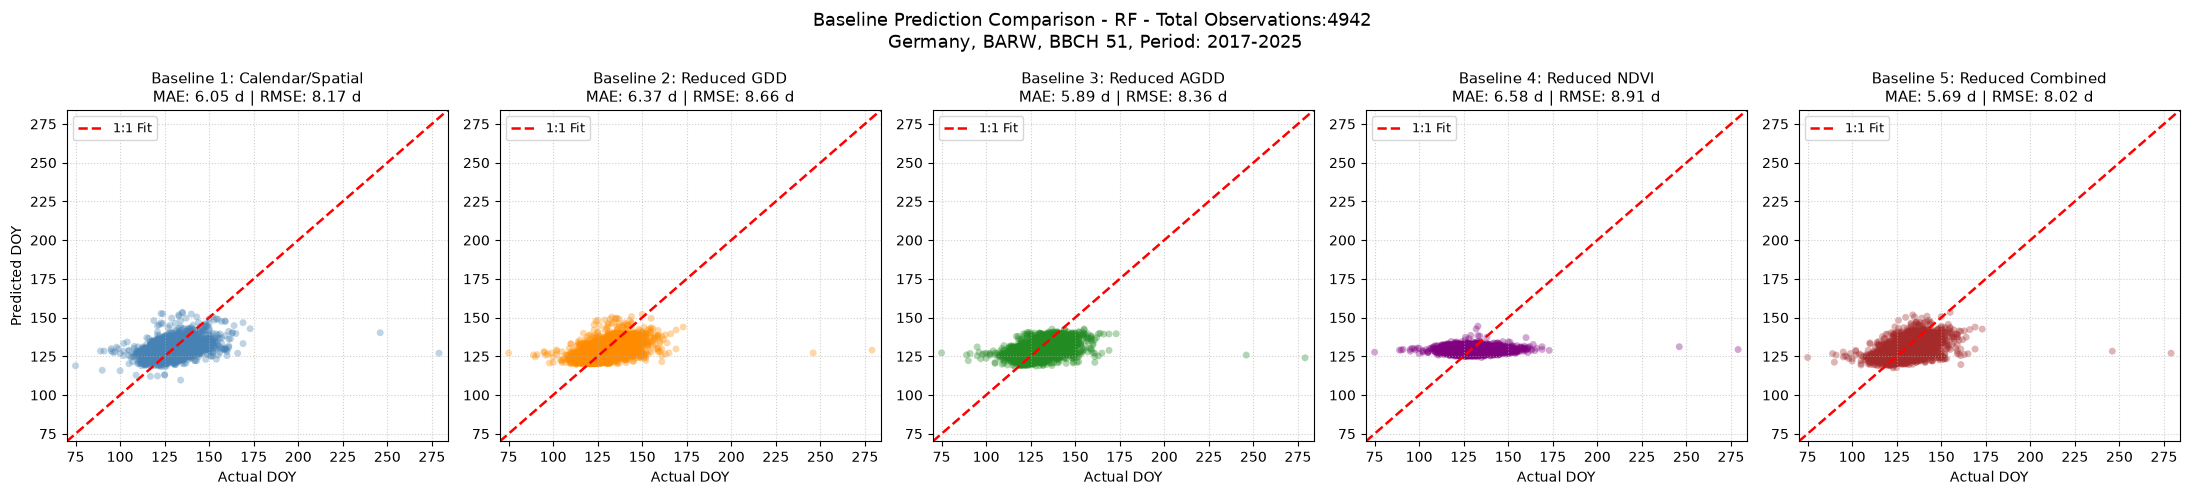

In [44]:
# Define uniform axis limits so all 5 subplots share an identical 1:1 scale
min_val = min(actual_doy) - 5
max_val = max(actual_doy) + 5

models_plot = [
    ("Baseline 1: Calendar/Spatial", b1_preds, overall_b1_mae, overall_b1_rmse, "steelblue"),
    ("Baseline 2: Reduced GDD", b2_preds, overall_b2_mae, overall_b2_rmse, "darkorange"),
    ("Baseline 3: Reduced AGDD", b3_preds, overall_b3_mae, overall_b3_rmse, "forestgreen"),
    ("Baseline 4: Reduced NDVI", b4_preds, overall_b4_mae, overall_b4_rmse, "purple"),
    ("Baseline 5: Reduced Combined", b5_preds, overall_b5_mae, overall_b5_rmse, "brown"),
]

plt.figure(figsize=(22, 5))

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot, 1):
    plt.subplot(1, 5, i)
    plt.scatter(actual_doy, predictions, alpha=0.35, color=color, edgecolors="none", s=25)
    plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=1.8, label="1:1 Fit")
    
    plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d", fontsize=11)
    plt.xlabel("Actual DOY", fontsize=10)
    
    # Label the y-axis on the leftmost subplot to prevent label overlap
    if i == 1:
        plt.ylabel("Predicted DOY", fontsize=10)
        
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", fontsize=9, frameon=True)

plt.tight_layout()
plt.subplots_adjust(top=0.78)
plt.suptitle(f"Baseline Prediction Comparison - RF - Total Observations:{len(df_final)} \n{final_name}",
    fontsize=13,
    y=0.98,
)

# Save high-resolution figure to your results directory
save_fig_path = results_dir_baselines / "scatter_comparison_baselines_rf_reduced.png"
plt.savefig(save_fig_path, dpi=300, bbox_inches="tight")
print(f"Scatter plot matrix saved to: {save_fig_path.resolve()}")

plt.show()

### 3.8 $R^2$ Decomposition & Per-Year LOYOCV Trajectory Plots (Random Forest, Reduced Features)

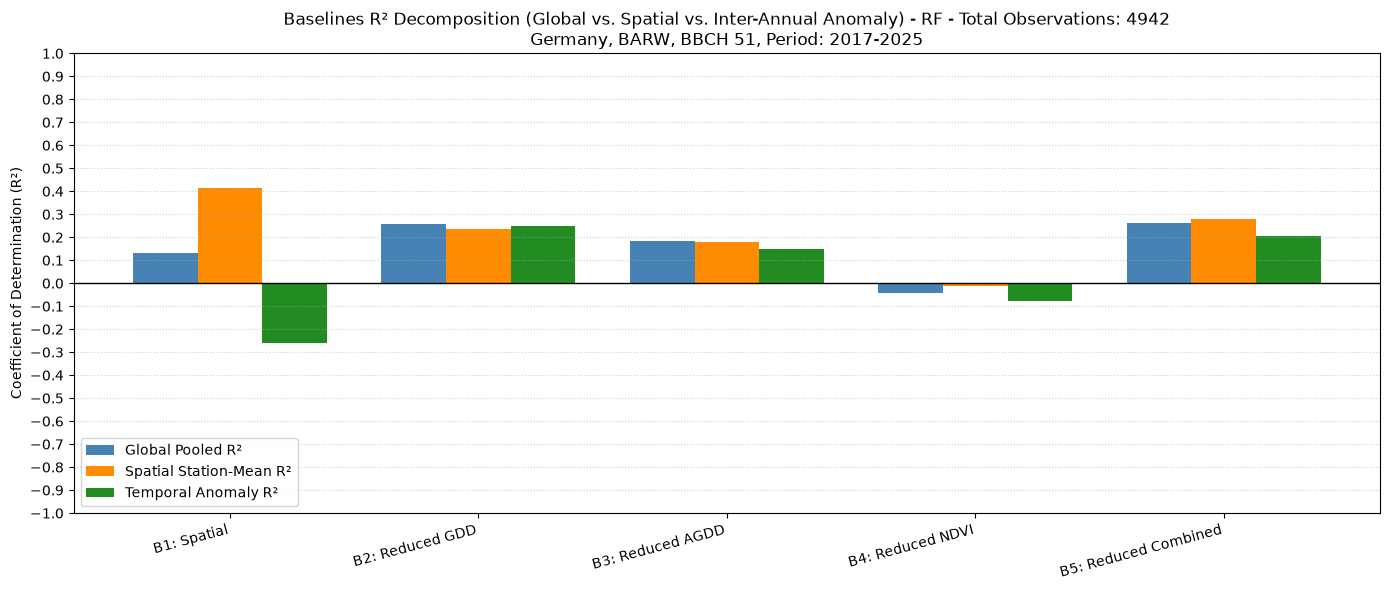

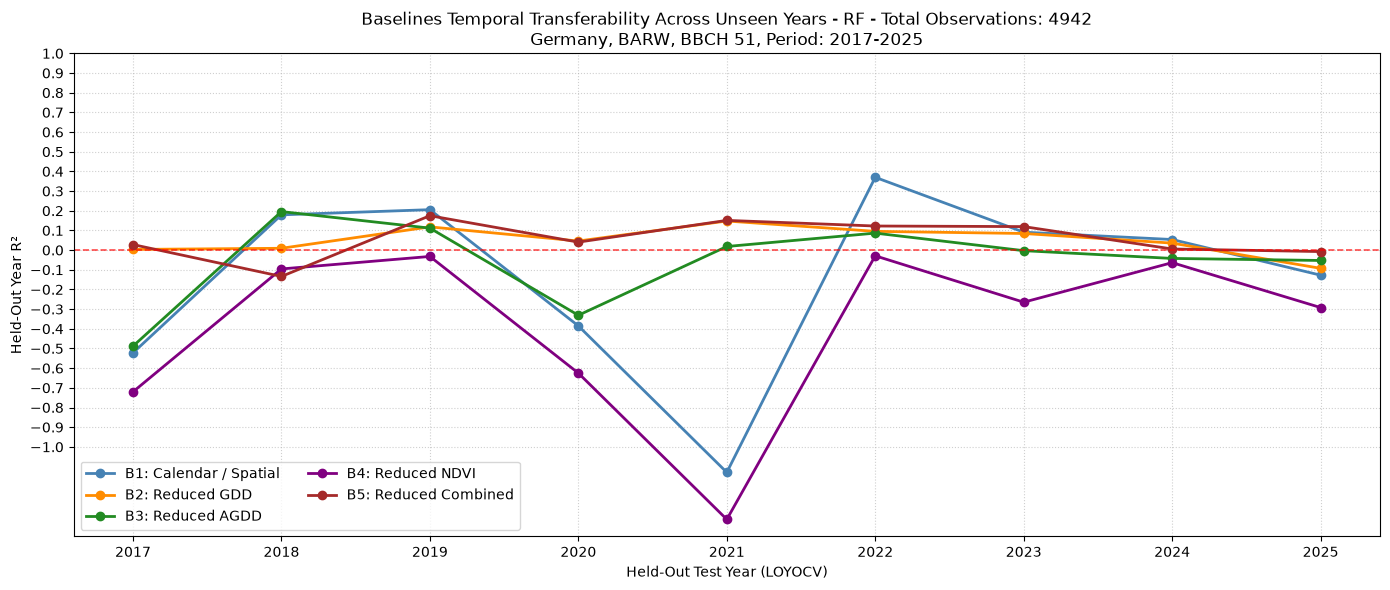

In [45]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array for boolean masking
actual_doy_arr = np.asarray(actual_doy)

# Build station identifier from df_reduced to separate spatial vs. temporal variance
if "PEP_ID" in df_reduced.columns:
    station_ids = df_reduced["PEP_ID"].values
else:
    station_ids = (
        df_reduced["Latitude"].round(4).astype(str)
        + "_"
        + df_reduced["Longitude"].round(4).astype(str)
    ).values

years_arr = df_reduced["Year"].astype(int).values

baseline_r2_models = [
    ("B1: Calendar / Spatial", np.asarray(b1_preds), "steelblue"),
    ("B2: Reduced GDD", np.asarray(b2_preds), "darkorange"),
    ("B3: Reduced AGDD", np.asarray(b3_preds), "forestgreen"),
    ("B4: Reduced NDVI", np.asarray(b4_preds), "purple"),
    ("B5: Reduced Combined", np.asarray(b5_preds), "brown"),
]

# R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R² (RF)
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    "B1: Spatial",
    "B2: Reduced GDD",
    "B3: Reduced AGDD",
    "B4: Reduced NDVI",
    "B5: Reduced Combined",
]

for _, preds, _ in baseline_r2_models:
    # 1. Global Pooled R²
    g_r2 = r2_score(actual_doy_arr, preds)

    # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
    df_tmp = pd.DataFrame({
        "Station": station_ids,
        "Actual": actual_doy_arr,
        "Pred": preds,
    })
    st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
    s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

    df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
    obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
    pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
    t_r2 = r2_score(obs_anom, pred_anom)

    global_r2_list.append(g_r2)
    spatial_r2_list.append(s_r2)
    temporal_r2_list.append(t_r2)

# Save R² Decomposition values to CSV
df_r2_decomposition = pd.DataFrame({
    "Model_Key": [f"B{i}" for i in range(1, len(baseline_r2_models) + 1)],
    "Model_Label": short_labels,
    "Global_Pooled_R2": np.round(global_r2_list, 4),
    "Spatial_Station_Mean_R2": np.round(spatial_r2_list, 4),
    "Temporal_Anomaly_R2": np.round(temporal_r2_list, 4),
})
display(df_r2_decomposition)
df_r2_decomposition.to_csv(
    results_dir_baselines / "r2_decomposition_baselines_rf_reduced.csv",
    sep=";",
    index=False,
)

x_pos = np.arange(len(baseline_r2_models))
bar_width = 0.26

plt.figure(figsize=(14, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R²",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.yticks(y_ticks)
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"Baselines R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) - "
    f"RF - Total Observations: {len(df_reduced)}\n{final_name}"
)
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.savefig(
    results_dir_baselines / "r2_decomposition_baselines_rf_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# -------------------------------------------------------------------------
# 2. Per-Year LOYOCV R² Trajectory Across Held-Out Years (RF)
# -------------------------------------------------------------------------
unique_years_plot = sorted(np.unique(years_arr))
df_r2_per_year = pd.DataFrame({"Test_Year": unique_years_plot})

plt.figure(figsize=(14, 6))

for idx, (m_label, preds, color) in enumerate(baseline_r2_models, start=1):
    yearly_r2 = []
    for yr in unique_years_plot:
        mask = years_arr == yr
        yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

    df_r2_per_year[f"B{idx}_R2"] = np.round(yearly_r2, 4)

    plt.plot(
        unique_years_plot,
        yearly_r2,
        marker="o",
        lw=2,
        color=color,
        label=m_label,
    )

# Save Per-Year R² values to CSV
display(df_r2_per_year)
df_r2_per_year.to_csv(
    results_dir_baselines / "r2_per_year_baselines_rf_reduced.csv",
    sep=";",
    index=False,
)

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"Baselines Temporal Transferability Across Unseen Years - RF - "
    f"Total Observations: {len(df_reduced)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.xticks(unique_years_plot)
plt.yticks(y_ticks)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    results_dir_baselines / "r2_per_year_baselines_rf_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### 3.9 LOYOCV Hyperparameter Search (XGBoost, Reduced Features)

In [ ]:
# HYPERPARAMETER SEARCH ACROSS EACH BASELINE
print("=" * 80)
print("RUNNING LOYOCV HYPERPARAMETER SEARCH FOR BASELINES 1 TO 5 - XGBOOST")
print("=" * 80)

for model_key, feat_cols in models_to_tune.items():
    print(f"\nTuning {model_key} (Total Features: {len(feat_cols)})...")

    X_subset = df_reduced[feat_cols]

    # Adapt feature subsampling ratio to feature space size
    if len(feat_cols) <= 3:
        colsample_dist = [1.0]
    else:
        colsample_dist = uniform(0.30, 0.50)  # Randomly samples between 30% and 80%

    xgb_param_distributions = {
        # Ensemble size and shrinkage
        "n_estimators": randint(150, 350),
        "learning_rate": uniform(0.02, 0.08),  # Range: 0.02 to 0.10
        # Tree architecture (keep shallow for small N)
        "max_depth": randint(3, 6),            # Depths 3, 4, 5
        "min_child_weight": randint(2, 7),     # Analogous to min_samples_leaf (2 to 6)
        "gamma": uniform(0.0, 1.5),            # Minimum loss reduction for a split
        # Stochastic sampling
        "subsample": uniform(0.65, 0.30),      # Row subsampling (0.65 to 0.95)
        "colsample_bytree": colsample_dist,    # Column subsampling
        # Regularization
        "reg_alpha": [0.0, 0.1, 1.0],
        "reg_lambda": [1.0, 3.0, 8.0],
    }

    xgb_search = RandomizedSearchCV(
        estimator=XGBRegressor(
            objective="reg:squarederror",
            eval_metric="mae",
            random_state=42,
            n_jobs=1,  # Keep inner booster single-threaded
        ),
        param_distributions=xgb_param_distributions,
        n_iter=25,
        scoring="neg_mean_absolute_error",
        cv=logo,
        random_state=42,
        n_jobs=-1,  # Parallelize across CV folds/iterations
        verbose=0,
    )

    # Fit using groups to enforce Leave-One-Year-Out validation
    xgb_search.fit(X_subset, y_all, groups=groups_all)

    best_params_dict[model_key] = xgb_search.best_params_
    print(f" -> Best LOYOCV MAE: {-xgb_search.best_score_:.2f} days")
    print(f" -> Optimal Parameters: {xgb_search.best_params_}")

print("=" * 75)
print("FEATURE REDUCTION SUMMARY (FULL-YEAR CALENDAR)")
print("=" * 75)
print(f"Total Observation Records:               {len(df_reduced)}")
print(f"Baseline 1 (Calendar & Spatial):         {len(features_b1):3d} features")
print(f"Baseline 2 (GDD - 12 Months + Stress):   {len(features_b2):3d} features")
print(f"Baseline 3 (AGDD - 26 Bi-Weekly Steps):  {len(features_b3):3d} features")
print(f"Baseline 4 (NDVI - LSP Metrics + ANDVI): {len(features_b4):3d} features")
print(f"Baseline 5 (Combined Multimodal B1-B4):  {len(features_b5):3d} features")
print("=" * 75)

RUNNING LOYOCV HYPERPARAMETER SEARCH FOR BASELINES 1 TO 5 - XGBOOST

Tuning B1 (Total Features: 2)...
 -> Best LOYOCV MAE: 6.08 days
 -> Optimal Parameters: {'colsample_bytree': 1.0, 'gamma': np.float64(0.3045918371021541), 'learning_rate': np.float64(0.09542828564463848), 'max_depth': 5, 'min_child_weight': 4, 'n_estimators': 235, 'reg_alpha': 0.1, 'reg_lambda': 3.0, 'subsample': np.float64(0.8924361138693251)}

Tuning B2 (Total Features: 14)...
 -> Best LOYOCV MAE: 5.16 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.559395310871683), 'gamma': np.float64(1.0545284383427669), 'learning_rate': np.float64(0.04909036819034352), 'max_depth': 3, 'min_child_weight': 3, 'n_estimators': 201, 'reg_alpha': 0.1, 'reg_lambda': 8.0, 'subsample': np.float64(0.7991745517677157)}

Tuning B3 (Total Features: 28)...
 -> Best LOYOCV MAE: 5.54 days
 -> Optimal Parameters: {'colsample_bytree': np.float64(0.6037724259507191), 'gamma': np.float64(0.2557861855309373), 'learning_rate': np.float

### 3.10 Run LOYOCV Evaluation & Summarize Reduced Baseline Results (XGBoost)

In [21]:
# 5. EXECUTE LEAVE-ONE-YEAR-OUT CROSS-VALIDATION (LOYOCV) ON REDUCED BASELINES
unique_years = sorted(df_reduced["Year"].unique())

b1_preds, b2_preds, b3_preds, b4_preds, b5_preds = [], [], [], [], []
actual_doy = []
test_years_list = []
fold_results = []

print(f"\nStarting LOYOCV across {len(unique_years)} annual folds...\n")

for test_year in unique_years:
    train_mask = df_reduced["Year"] != test_year
    test_mask = df_reduced["Year"] == test_year

    y_train = df_reduced.loc[train_mask, "DOY"]
    y_test = df_reduced.loc[test_mask, "DOY"]

    # Model definition: trees can now split cleanly without noise dilution

    # Fit B1
    xgb_b1 = XGBRegressor(**best_params_dict["B1"], random_state=42, n_jobs=1)
    xgb_b1.fit(df_reduced.loc[train_mask, features_b1], y_train)
    pred_b1 = xgb_b1.predict(df_reduced.loc[test_mask, features_b1])

    # Fit B2
    xgb_b2 = XGBRegressor(**best_params_dict["B2"], random_state=42, n_jobs=1)
    xgb_b2.fit(df_reduced.loc[train_mask, features_b2], y_train)
    pred_b2 = xgb_b2.predict(df_reduced.loc[test_mask, features_b2])

    # Fit B3
    xgb_b3 = XGBRegressor(**best_params_dict["B3"], random_state=42, n_jobs=1)
    xgb_b3.fit(df_reduced.loc[train_mask, features_b3], y_train)
    pred_b3 = xgb_b3.predict(df_reduced.loc[test_mask, features_b3])

    # Fit B4
    xgb_b4 = XGBRegressor(**best_params_dict["B4"], random_state=42, n_jobs=1)
    xgb_b4.fit(df_reduced.loc[train_mask, features_b4], y_train)
    pred_b4 = xgb_b4.predict(df_reduced.loc[test_mask, features_b4])

    # Fit B5
    xgb_b5 = XGBRegressor(**best_params_dict["B5"], random_state=42, n_jobs=1)
    xgb_b5.fit(df_reduced.loc[train_mask, features_b5], y_train)
    pred_b5 = xgb_b5.predict(df_reduced.loc[test_mask, features_b5])

    # Compute fold-level MAE
    mae_b1 = mean_absolute_error(y_test, pred_b1)
    mae_b2 = mean_absolute_error(y_test, pred_b2)
    mae_b3 = mean_absolute_error(y_test, pred_b3)
    mae_b4 = mean_absolute_error(y_test, pred_b4)
    mae_b5 = mean_absolute_error(y_test, pred_b5)

    # Compute fold-level RMSE
    rmse_b1 = np.sqrt(mean_squared_error(y_test, pred_b1))
    rmse_b2 = np.sqrt(mean_squared_error(y_test, pred_b2))
    rmse_b3 = np.sqrt(mean_squared_error(y_test, pred_b3))
    rmse_b4 = np.sqrt(mean_squared_error(y_test, pred_b4))
    rmse_b5 = np.sqrt(mean_squared_error(y_test, pred_b5))

    fold_results.append({
        "Test_Year": test_year,
        "N_Samples": len(y_test),
        "B1_Calendar_MAE": round(mae_b1, 2),
        "B1_Calendar_RMSE": round(rmse_b1, 2),
        "B2_ReducedGDD_MAE": round(mae_b2, 2),
        "B2_ReducedGDD_RMSE": round(rmse_b2, 2),
        "B3_ReducedAGDD_MAE": round(mae_b3, 2),
        "B3_ReducedAGDD_RMSE": round(rmse_b3, 2),
        "B4_ReducedNDVI_MAE": round(mae_b4, 2),
        "B4_ReducedNDVI_RMSE": round(rmse_b4, 2),
        "B5_ReducedCombined_MAE": round(mae_b5, 2),
        "B5_ReducedCombined_RMSE": round(rmse_b5, 2),
    })

    b1_preds.extend(pred_b1)
    b2_preds.extend(pred_b2)
    b3_preds.extend(pred_b3)
    b4_preds.extend(pred_b4)
    b5_preds.extend(pred_b5)
    actual_doy.extend(y_test.values)
    test_years_list.extend([test_year] * len(y_test))

    print(
        f"Year {test_year} (N={len(y_test):3d}) | "
        f"B1: {mae_b1:5.2f}d | B2: {mae_b2:5.2f}d | "
        f"B3: {mae_b3:5.2f}d | B4: {mae_b4:5.2f}d | B5: {mae_b5:5.2f}d"
    )

print("\nLOYOCV execution finished!")

# 6. POOLED METRICS AND SUMMARY EXPORT
df_folds_reduced = pd.DataFrame(fold_results)

# Micro-averaged pooled metrics across all held-out sample years
overall_b1_mae = mean_absolute_error(actual_doy, b1_preds)
overall_b1_rmse = np.sqrt(mean_squared_error(actual_doy, b1_preds))

overall_b2_mae = mean_absolute_error(actual_doy, b2_preds)
overall_b2_rmse = np.sqrt(mean_squared_error(actual_doy, b2_preds))

overall_b3_mae = mean_absolute_error(actual_doy, b3_preds)
overall_b3_rmse = np.sqrt(mean_squared_error(actual_doy, b3_preds))

overall_b4_mae = mean_absolute_error(actual_doy, b4_preds)
overall_b4_rmse = np.sqrt(mean_squared_error(actual_doy, b4_preds))

overall_b5_mae = mean_absolute_error(actual_doy, b5_preds)
overall_b5_rmse = np.sqrt(mean_squared_error(actual_doy, b5_preds))

print("=" * 85)
print("POOLED LOYOCV RESULTS: REDUCED BASELINE HIERARCHY")
print("=" * 85)
print(f"Baseline 1 (Calendar & Spatial):         MAE: {overall_b1_mae:5.2f} d | RMSE: {overall_b1_rmse:5.2f} d")
print(f"Baseline 2 (Reduced 12M GDD + Stress):   MAE: {overall_b2_mae:5.2f} d | RMSE: {overall_b2_rmse:5.2f} d")
print(f"Baseline 3 (Reduced 26-Step AGDD):       MAE: {overall_b3_mae:5.2f} d | RMSE: {overall_b3_rmse:5.2f} d")
print(f"Baseline 4 (Reduced NDVI LSP + ANDVI):   MAE: {overall_b4_mae:5.2f} d | RMSE: {overall_b4_rmse:5.2f} d")
print(f"Baseline 5 (Reduced Combined Multimodal):MAE: {overall_b5_mae:5.2f} d | RMSE: {overall_b5_rmse:5.2f} d")
print("-" * 85)
print(f"Difference B5 vs B1 (Combined vs Spatial): {overall_b5_mae - overall_b1_mae:+5.2f} d MAE")
print("=" * 85)

display(df_folds_reduced)

# 7. SAVE RESULTS
summary_path = results_dir_baselines / "baselines_loyocv_results_reduced_xgboost.csv"
df_folds_reduced.to_csv(summary_path, sep=";", index=False)
print(f"\nSaved fold summary to: {summary_path.resolve()}")


Starting LOYOCV across 9 annual folds...

Year 2017 (N=621) | B1:  6.19d | B2:  4.26d | B3:  5.83d | B4:  6.36d | B5:  4.26d
Year 2018 (N=598) | B1:  4.31d | B2:  4.80d | B3:  4.19d | B4:  5.13d | B5:  5.23d
Year 2019 (N=592) | B1:  5.70d | B2:  5.79d | B3:  5.98d | B4:  6.59d | B5:  5.59d
Year 2020 (N=579) | B1:  6.92d | B2:  5.18d | B3:  6.61d | B4:  7.35d | B5:  5.28d
Year 2021 (N=543) | B1:  9.30d | B2:  4.73d | B3:  5.14d | B4:  9.16d | B5:  4.87d
Year 2022 (N=529) | B1:  3.54d | B2:  4.43d | B3:  4.42d | B4:  4.59d | B5:  4.38d
Year 2023 (N=511) | B1:  4.48d | B2:  4.14d | B3:  4.51d | B4:  5.05d | B5:  4.08d
Year 2024 (N=488) | B1:  6.48d | B2:  5.64d | B3:  6.02d | B4:  7.17d | B5:  5.76d
Year 2025 (N=481) | B1:  7.75d | B2:  7.45d | B3:  7.17d | B4:  8.25d | B5:  6.97d

LOYOCV execution finished!
POOLED LOYOCV RESULTS: REDUCED BASELINE HIERARCHY
Baseline 1 (Calendar & Spatial):         MAE:  6.05 d | RMSE:  8.16 d
Baseline 2 (Reduced 12M GDD + Stress):   MAE:  5.12 d | RMSE: 

,Test_Year,N_Samples,B1_Calendar_MAE,B1_Calendar_RMSE,B2_ReducedGDD_MAE,B2_ReducedGDD_RMSE,B3_ReducedAGDD_MAE,B3_ReducedAGDD_RMSE,B4_ReducedNDVI_MAE,B4_ReducedNDVI_RMSE,B5_ReducedCombined_MAE,B5_ReducedCombined_RMSE
0,2017,621,6.19,7.48,4.26,6.05,5.83,7.39,6.36,7.95,4.26,5.97
1,2018,598,4.31,5.85,4.80,6.43,4.19,5.79,5.13,6.76,5.23,6.87
2,2019,592,5.70,7.46,5.79,7.86,5.98,7.89,6.59,8.51,5.59,7.61
3,2020,579,6.92,8.32,5.18,6.90,6.61,8.16,7.35,9.01,5.28,6.92
4,2021,543,9.30,10.64,4.73,6.73,5.14,7.22,9.16,11.22,4.87,6.72
5,2022,529,3.54,5.05,4.43,6.05,4.42,6.08,4.59,6.45,4.38,5.96
6,2023,511,4.48,6.04,4.14,6.06,4.51,6.35,5.05,7.13,4.08,5.95
7,2024,488,6.48,11.49,5.64,11.60,6.02,12.06,7.17,12.18,5.76,11.78
8,2025,481,7.75,9.46,7.45,9.31,7.17,9.14,8.25,10.13,6.97,8.94



Saved fold summary to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_BASELINES\baselines_loyocv_results_reduced_xgboost.csv


### 3.11 Scatter Plots (XGBoost, Reduced Features)

Scatter plot matrix saved to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_BASELINES\scatter_comparison_baselines_xgboost_reduced.png


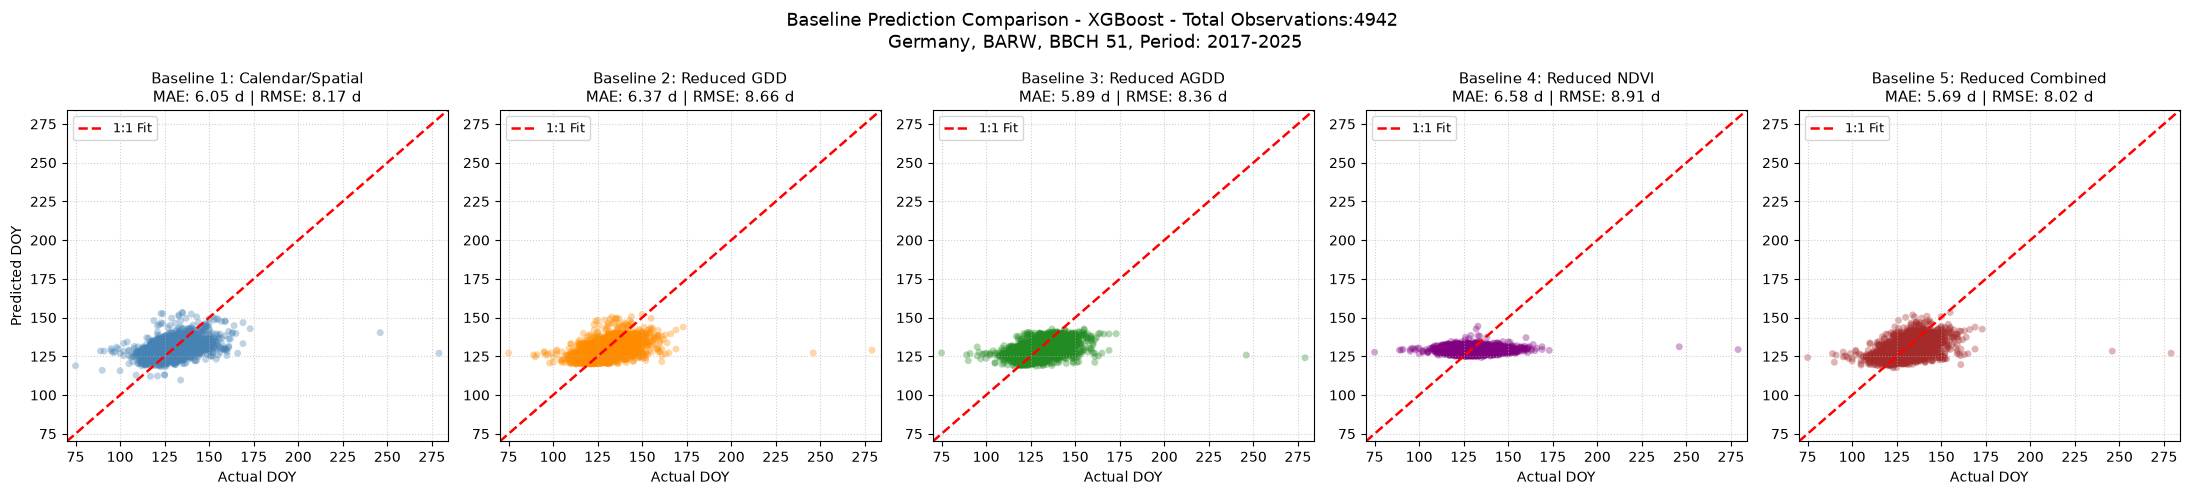

In [ ]:
models_plot = [
    ("Baseline 1: Calendar/Spatial", b1_preds, overall_b1_mae, overall_b1_rmse, "steelblue"),
    ("Baseline 2: Reduced GDD", b2_preds, overall_b2_mae, overall_b2_rmse, "darkorange"),
    ("Baseline 3: Reduced AGDD", b3_preds, overall_b3_mae, overall_b3_rmse, "forestgreen"),
    ("Baseline 4: Reduced NDVI", b4_preds, overall_b4_mae, overall_b4_rmse, "purple"),
    ("Baseline 5: Reduced Combined", b5_preds, overall_b5_mae, overall_b5_rmse, "brown"),
]

plt.figure(figsize=(22, 5))

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot, 1):
    plt.subplot(1, 5, i)
    plt.scatter(actual_doy, predictions, alpha=0.35, color=color, edgecolors="none", s=25)
    plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=1.8, label="1:1 Fit")
    
    plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d", fontsize=11)
    plt.xlabel("Actual DOY", fontsize=10)
    
    # Label the y-axis on the leftmost subplot to prevent label overlap
    if i == 1:
        plt.ylabel("Predicted DOY", fontsize=10)
        
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", fontsize=9, frameon=True)

plt.tight_layout()
plt.subplots_adjust(top=0.78)
plt.suptitle(f"Baseline Prediction Comparison - XGBoost - Total Observations:{len(df_final)} \n{final_name}",
    fontsize=13,
    y=0.98,
)

# Save high-resolution figure to your results directory
save_fig_path = results_dir_baselines / "scatter_comparison_baselines_xgboost_reduced.png"
plt.savefig(save_fig_path, dpi=300, bbox_inches="tight")
print(f"Scatter plot matrix saved to: {save_fig_path.resolve()}")

plt.show()

### 3.12 $R^2$ Decomposition & Per-Year LOYOCV Trajectory Plots (XGBoost, Reduced Features)

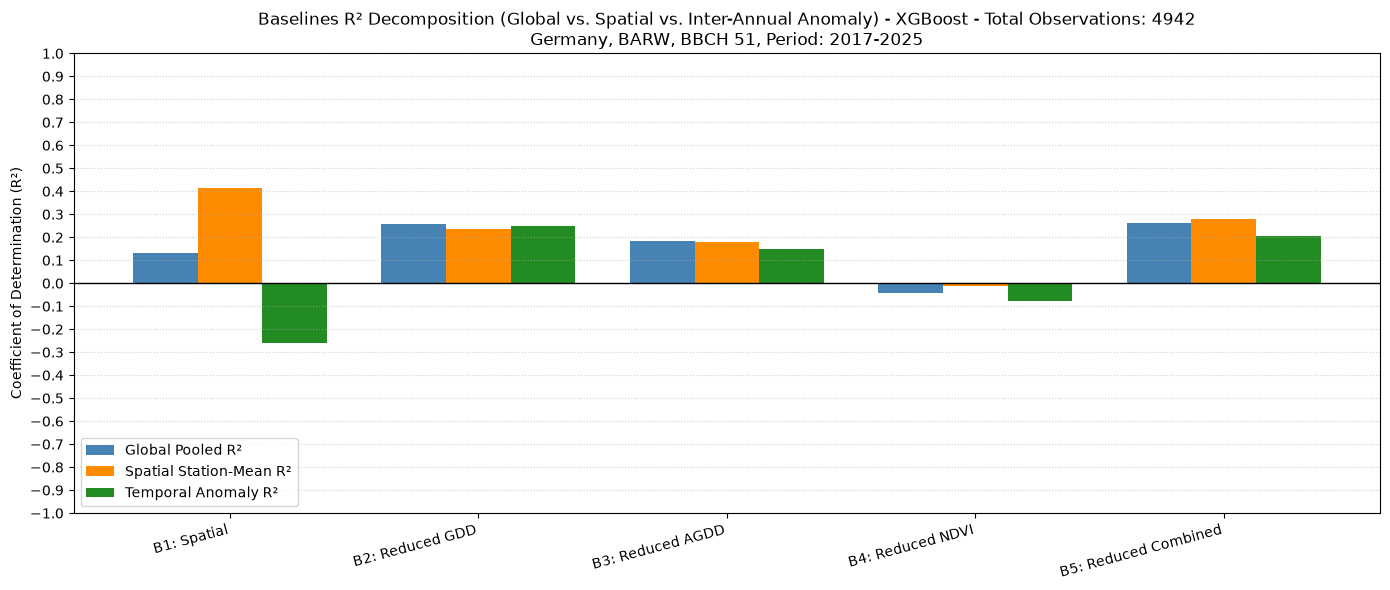

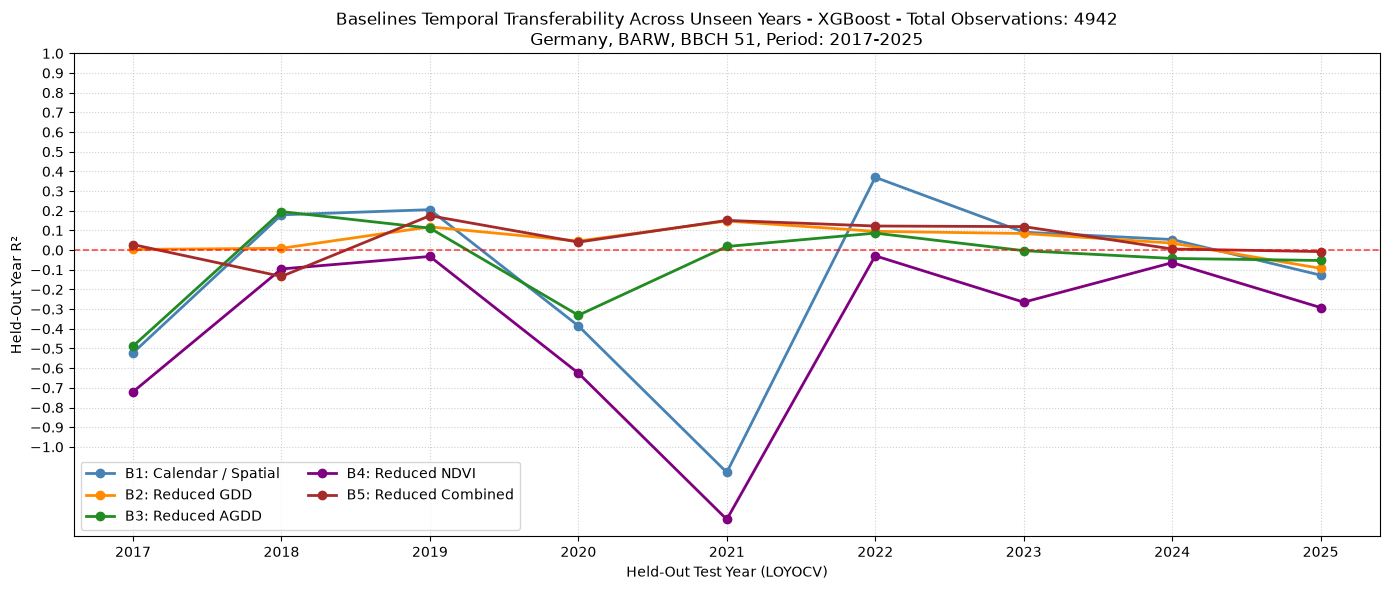

In [56]:
from sklearn.metrics import r2_score

# Ensure actual_doy is a NumPy array for boolean masking
actual_doy_arr = np.asarray(actual_doy)

# Build station identifier from df_reduced to separate spatial vs. temporal variance
if "PEP_ID" in df_reduced.columns:
    station_ids = df_reduced["PEP_ID"].values
else:
    station_ids = (
        df_reduced["Latitude"].round(4).astype(str)
        + "_"
        + df_reduced["Longitude"].round(4).astype(str)
    ).values

years_arr = df_reduced["Year"].astype(int).values

baseline_r2_models = [
    ("B1: Calendar / Spatial", np.asarray(b1_preds), "steelblue"),
    ("B2: Reduced GDD", np.asarray(b2_preds), "darkorange"),
    ("B3: Reduced AGDD", np.asarray(b3_preds), "forestgreen"),
    ("B4: Reduced NDVI", np.asarray(b4_preds), "purple"),
    ("B5: Reduced Combined", np.asarray(b5_preds), "brown"),
]

# R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R² (XGBoost)
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    "B1: Spatial",
    "B2: Reduced GDD",
    "B3: Reduced AGDD",
    "B4: Reduced NDVI",
    "B5: Reduced Combined",
]

for _, preds, _ in baseline_r2_models:
    # 1. Global Pooled R²
    g_r2 = r2_score(actual_doy_arr, preds)

    # 2. Spatial Station-Mean R² & 3. Temporal Anomaly R² (ΔDOY)
    df_tmp = pd.DataFrame({
        "Station": station_ids,
        "Actual": actual_doy_arr,
        "Pred": preds,
    })
    st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
    s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

    df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
    obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
    pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
    t_r2 = r2_score(obs_anom, pred_anom)

    global_r2_list.append(g_r2)
    spatial_r2_list.append(s_r2)
    temporal_r2_list.append(t_r2)

# Save R² Decomposition values to CSV
df_r2_decomposition = pd.DataFrame({
    "Model_Key": [f"B{i}" for i in range(1, len(baseline_r2_models) + 1)],
    "Model_Label": short_labels,
    "Global_Pooled_R2": np.round(global_r2_list, 4),
    "Spatial_Station_Mean_R2": np.round(spatial_r2_list, 4),
    "Temporal_Anomaly_R2": np.round(temporal_r2_list, 4),
})
display(df_r2_decomposition)
df_r2_decomposition.to_csv(
    results_dir_baselines / "r2_decomposition_baselines_xgboost_reduced.csv",
    sep=";",
    index=False,
)

x_pos = np.arange(len(baseline_r2_models))
bar_width = 0.26

plt.figure(figsize=(14, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R²",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.yticks(y_ticks)
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"Baselines R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) - "
    f"XGBoost - Total Observations: {len(df_reduced)}\n{final_name}"
)
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="lower left", frameon=True)

plt.tight_layout()
plt.savefig(
    results_dir_baselines / "r2_decomposition_baselines_xgboost_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Per-Year LOYOCV R² Trajectory Across Held-Out Years (XGBoost)
unique_years_plot = sorted(np.unique(years_arr))
df_r2_per_year = pd.DataFrame({"Test_Year": unique_years_plot})

plt.figure(figsize=(14, 6))

for idx, (m_label, preds, color) in enumerate(baseline_r2_models, start=1):
    yearly_r2 = []
    for yr in unique_years_plot:
        mask = years_arr == yr
        yearly_r2.append(r2_score(actual_doy_arr[mask], preds[mask]))

    df_r2_per_year[f"B{idx}_R2"] = np.round(yearly_r2, 4)

    plt.plot(
        unique_years_plot,
        yearly_r2,
        marker="o",
        lw=2,
        color=color,
        label=m_label,
    )

# Save Per-Year R² values to CSV
display(df_r2_per_year)
df_r2_per_year.to_csv(
    results_dir_baselines / "r2_per_year_baselines_xgboost_reduced.csv",
    sep=";",
    index=False,
)

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"Baselines Temporal Transferability Across Unseen Years - XGBoost - "
    f"Total Observations: {len(df_reduced)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.xticks(unique_years_plot)
plt.yticks(y_ticks)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    results_dir_baselines / "r2_per_year_baselines_xgboost_reduced.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Part 4: Leak-Free MiniRocket Time-Series Feature Extraction (Top 10 Kernels)
### 4.1 Extract MiniRocket Kernels, Tune Pipelines, Evaluate LOYOCV & Generate Scatter Plots

1. EXTRACTING MINIROCKET KERNEL ACTIVATIONS (10,000 PPVs)
GDD Convolutions:  9996 features extracted.
NDVI Convolutions: 9996 features extracted.

2. HYPERPARAMETER TUNING VIA LEAKAGE-FREE PIPELINE (SELECTKBEST k=10)

Tuning GDD MiniRocket Pipelines (Top 10 Kernels)...
 -> GDD (RF) Best LOYOCV MAE:  5.86 days
 -> GDD (XGB) Best LOYOCV MAE: 5.86 days

Tuning NDVI MiniRocket Pipelines (Top 10 Kernels)...
 -> NDVI (RF) Best LOYOCV MAE:  6.65 days
 -> NDVI (XGB) Best LOYOCV MAE: 6.65 days

3. EVALUATING LOYOCV ACROSS 9 FOLDS
Year 2017 (N=621) | GDD(RF):  5.14d | GDD(XGB):  5.42d | NDVI(RF):  6.64d | NDVI(XGB):  6.64d
Year 2018 (N=598) | GDD(RF):  4.95d | GDD(XGB):  4.39d | NDVI(RF):  5.19d | NDVI(XGB):  5.21d
Year 2019 (N=592) | GDD(RF):  5.80d | GDD(XGB):  5.77d | NDVI(RF):  6.59d | NDVI(XGB):  6.61d
Year 2020 (N=579) | GDD(RF):  7.20d | GDD(XGB):  6.90d | NDVI(RF):  6.98d | NDVI(XGB):  7.01d
Year 2021 (N=543) | GDD(RF):  5.15d | GDD(XGB):  5.21d | NDVI(RF):  9.21d | NDVI(XGB):  9.19d
Yea

,Test_Year,N_Samples,GDD_Rocket_RF_MAE,GDD_Rocket_RF_RMSE,GDD_Rocket_XGB_MAE,GDD_Rocket_XGB_RMSE,NDVI_Rocket_RF_MAE,NDVI_Rocket_RF_RMSE,NDVI_Rocket_XGB_MAE,NDVI_Rocket_XGB_RMSE
0,2017,621,5.14,6.73,5.42,7.02,6.64,8.33,6.64,8.30
1,2018,598,4.95,6.42,4.39,5.98,5.19,6.88,5.21,6.91
2,2019,592,5.80,7.79,5.77,7.70,6.59,8.59,6.61,8.58
3,2020,579,7.20,8.68,6.90,8.41,6.98,8.70,7.01,8.72
4,2021,543,5.15,7.26,5.21,7.24,9.21,11.36,9.19,11.34
5,2022,529,4.56,6.41,4.44,6.35,4.65,6.60,4.61,6.56
6,2023,511,5.20,7.02,5.92,7.71,4.94,6.92,4.98,6.96
7,2024,488,6.01,11.97,5.93,11.86,7.89,12.58,7.79,12.49
8,2025,481,8.72,10.38,8.73,10.39,7.80,9.86,7.78,9.85


Scatter plot saved to: C:\Users\jimpa\Desktop\Thesis\Notebooks\Results\germany_barw_bbch51_2017-01-01_2025-12-31\LOYOCV_MINIROCKET\scatter_comparison_minirocket_leakage_free.png


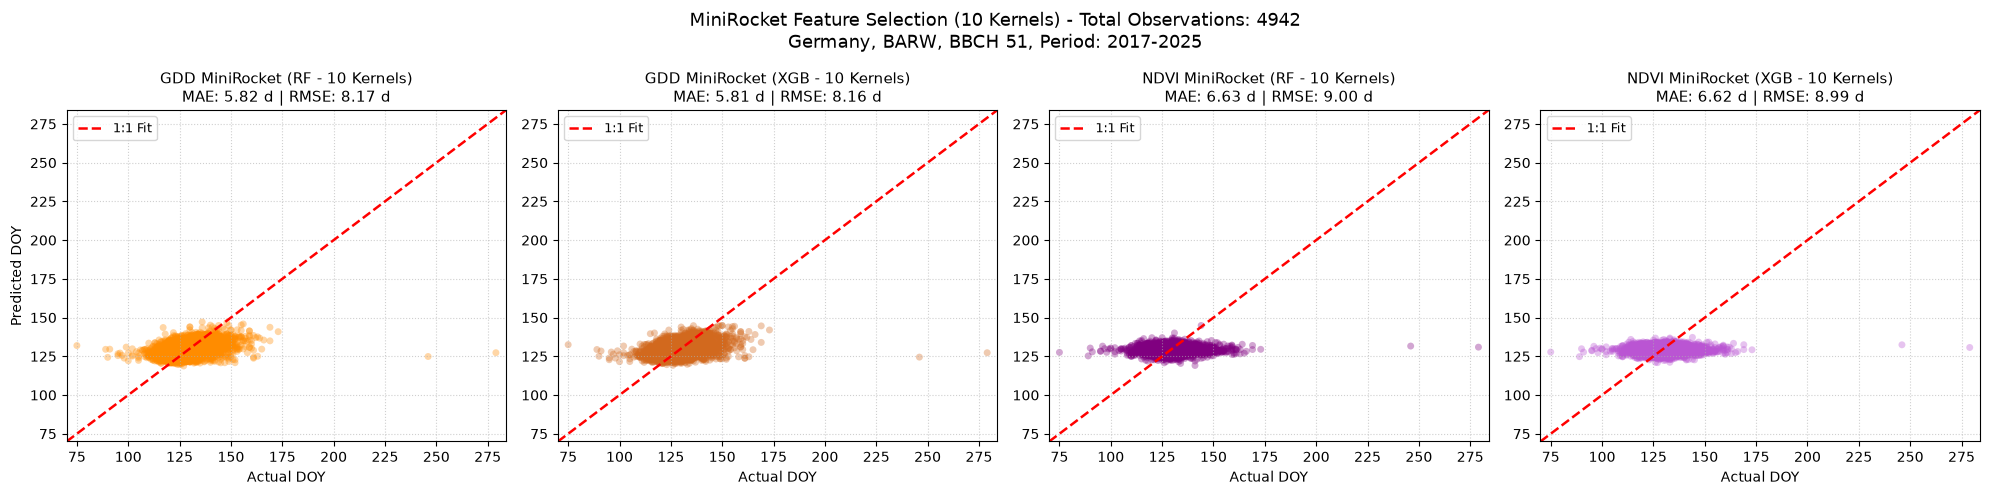

In [ ]:
# MINIROCKET PIPELINE: SUPERVISED KERNEL SELECTION (NO PCA)
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import randint, uniform
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import LeaveOneGroupOut, RandomizedSearchCV
from sktime.transformations.panel.rocket import MiniRocket
from xgboost import XGBRegressor

# EXTRACT 10,000 DETERMINISTIC MINIROCKET CONVOLUTIONS
print("=" * 80)
print("1. EXTRACTING MINIROCKET KERNEL ACTIVATIONS (10,000 PPVs)")
print("=" * 80)

# Reshape 2D matrices into 3D panel format for sktime: (n_samples, 1, 365)
X_gdd_raw = df_final[gdd_feature_cols_2017_onwards].values[:, np.newaxis, :]
X_ndvi_raw = df_final[ndvi_feature_cols_2017_onwards].values[:, np.newaxis, :]

# MiniRocket uses fixed, non-learnable kernels (independent of target y)
minirocket_gdd = MiniRocket(random_state=42)
X_gdd_10k = minirocket_gdd.fit_transform(X_gdd_raw).values

minirocket_ndvi = MiniRocket(random_state=42)
X_ndvi_10k = minirocket_ndvi.fit_transform(X_ndvi_raw).values

y_all = df_final["DOY"].values
groups_all = df_final["Year"].values
logo = LeaveOneGroupOut()

print(f"GDD Convolutions:  {X_gdd_10k.shape[1]} features extracted.")
print(f"NDVI Convolutions: {X_ndvi_10k.shape[1]} features extracted.")


# HYPERPARAMETER SEARCH INSIDE A LEAKAGE-FREE PIPELINE
# SelectKBest(k=10) inside the Pipeline ensures the top 10 kernels are selected
# strictly on the training splits during each CV iteration.

print("\n" + "=" * 80)
print("2. HYPERPARAMETER TUNING VIA LEAKAGE-FREE PIPELINE (SELECTKBEST k=10)")
print("=" * 80)

# Search space for Random Forest
rf_param_dist = {
    "rf__n_estimators": randint(150, 350),
    "rf__max_depth": [None, 8, 12, 16],
    "rf__min_samples_leaf": randint(1, 4),
    "rf__min_samples_split": randint(2, 6),
    "rf__max_features": uniform(0.3, 0.5),  # 30% to 80% of the 10 selected kernels
}

# Search space for XGBoost
xgb_param_dist = {
    "xgb__n_estimators": randint(150, 350),
    "xgb__learning_rate": uniform(0.02, 0.08),
    "xgb__max_depth": randint(3, 6),
    "xgb__min_child_weight": randint(2, 6),
    "xgb__gamma": uniform(0.0, 1.5),
    "xgb__subsample": uniform(0.65, 0.30),
    "xgb__colsample_bytree": uniform(0.40, 0.50),
    "xgb__reg_alpha": [0.0, 0.1, 1.0],
    "xgb__reg_lambda": [1.0, 3.0, 8.0],
}

# --- A. Tune GDD Pipelines ---
print("\nTuning GDD MiniRocket Pipelines (Top 10 Kernels)...")

pipe_gdd_rf = Pipeline([
    ("select", SelectKBest(score_func=f_regression, k=10)),
    ("rf", RandomForestRegressor(random_state=42, n_jobs=-1))
])
search_gdd_rf = RandomizedSearchCV(
    estimator=pipe_gdd_rf, param_distributions=rf_param_dist,
    n_iter=25, scoring="neg_mean_absolute_error", cv=logo, random_state=42, n_jobs=-1, verbose=0
)
search_gdd_rf.fit(X_gdd_10k, y_all, groups=groups_all)
print(f" -> GDD (RF) Best LOYOCV MAE:  {-search_gdd_rf.best_score_:.2f} days")

pipe_gdd_xgb = Pipeline([
    ("select", SelectKBest(score_func=f_regression, k=10)),
    ("xgb", XGBRegressor(objective="reg:squarederror", eval_metric="mae", random_state=42, n_jobs=1))
])
search_gdd_xgb = RandomizedSearchCV(
    estimator=pipe_gdd_xgb, param_distributions=xgb_param_dist,
    n_iter=25, scoring="neg_mean_absolute_error", cv=logo, random_state=42, n_jobs=-1, verbose=0
)
search_gdd_xgb.fit(X_gdd_10k, y_all, groups=groups_all)
print(f" -> GDD (XGB) Best LOYOCV MAE: {-search_gdd_xgb.best_score_:.2f} days")

# --- B. Tune NDVI Pipelines ---
print("\nTuning NDVI MiniRocket Pipelines (Top 10 Kernels)...")

pipe_ndvi_rf = Pipeline([
    ("select", SelectKBest(score_func=f_regression, k=10)),
    ("rf", RandomForestRegressor(random_state=42, n_jobs=-1))
])
search_ndvi_rf = RandomizedSearchCV(
    estimator=pipe_ndvi_rf, param_distributions=rf_param_dist,
    n_iter=25, scoring="neg_mean_absolute_error", cv=logo, random_state=42, n_jobs=-1, verbose=0
)
search_ndvi_rf.fit(X_ndvi_10k, y_all, groups=groups_all)
print(f" -> NDVI (RF) Best LOYOCV MAE:  {-search_ndvi_rf.best_score_:.2f} days")

pipe_ndvi_xgb = Pipeline([
    ("select", SelectKBest(score_func=f_regression, k=10)),
    ("xgb", XGBRegressor(objective="reg:squarederror", eval_metric="mae", random_state=42, n_jobs=1))
])
search_ndvi_xgb = RandomizedSearchCV(
    estimator=pipe_ndvi_xgb, param_distributions=xgb_param_dist,
    n_iter=25, scoring="neg_mean_absolute_error", cv=logo, random_state=42, n_jobs=-1, verbose=0
)
search_ndvi_xgb.fit(X_ndvi_10k, y_all, groups=groups_all)
print(f" -> NDVI (XGB) Best LOYOCV MAE: {-search_ndvi_xgb.best_score_:.2f} days")


# LOYOCV EVALUATION LOOP ACROSS HELD-OUT YEARS
print("\n" + "=" * 80)
print(f"3. EVALUATING LOYOCV ACROSS {len(unique_years_filtered)} FOLDS")
print("=" * 80)

rf_gdd_preds, xgb_gdd_preds = [], []
rf_ndvi_preds, xgb_ndvi_preds = [], []
actual_doy_rocket = []
fold_results_rocket = []

for test_year in unique_years_filtered:
    train_mask = (groups_all != test_year)
    test_mask = (groups_all == test_year)

    y_train, y_test = y_all[train_mask], y_all[test_mask]

    # 1. GDD Pipeline Fits (Trained strictly on train_mask)
    model_gdd_rf = search_gdd_rf.best_estimator_
    model_gdd_rf.fit(X_gdd_10k[train_mask], y_train)
    p_rf_gdd = model_gdd_rf.predict(X_gdd_10k[test_mask])

    model_gdd_xgb = search_gdd_xgb.best_estimator_
    model_gdd_xgb.fit(X_gdd_10k[train_mask], y_train)
    p_xgb_gdd = model_gdd_xgb.predict(X_gdd_10k[test_mask])

    # 2. NDVI Pipeline Fits (Trained strictly on train_mask)
    model_ndvi_rf = search_ndvi_rf.best_estimator_
    model_ndvi_rf.fit(X_ndvi_10k[train_mask], y_train)
    p_rf_ndvi = model_ndvi_rf.predict(X_ndvi_10k[test_mask])

    model_ndvi_xgb = search_ndvi_xgb.best_estimator_
    model_ndvi_xgb.fit(X_ndvi_10k[train_mask], y_train)
    p_xgb_ndvi = model_ndvi_xgb.predict(X_ndvi_10k[test_mask])

    # Accumulate out-of-fold metrics
    rf_gdd_preds.extend(p_rf_gdd)
    xgb_gdd_preds.extend(p_xgb_gdd)
    rf_ndvi_preds.extend(p_rf_ndvi)
    xgb_ndvi_preds.extend(p_xgb_ndvi)
    actual_doy_rocket.extend(y_test)

    fold_results_rocket.append({
        "Test_Year": test_year,
        "N_Samples": len(y_test),
        "GDD_Rocket_RF_MAE": round(mean_absolute_error(y_test, p_rf_gdd), 2),
        "GDD_Rocket_RF_RMSE": round(np.sqrt(mean_squared_error(y_test, p_rf_gdd)), 2),
        "GDD_Rocket_XGB_MAE": round(mean_absolute_error(y_test, p_xgb_gdd), 2),
        "GDD_Rocket_XGB_RMSE": round(np.sqrt(mean_squared_error(y_test, p_xgb_gdd)), 2),
        "NDVI_Rocket_RF_MAE": round(mean_absolute_error(y_test, p_rf_ndvi), 2),
        "NDVI_Rocket_RF_RMSE": round(np.sqrt(mean_squared_error(y_test, p_rf_ndvi)), 2),
        "NDVI_Rocket_XGB_MAE": round(mean_absolute_error(y_test, p_xgb_ndvi), 2),
        "NDVI_Rocket_XGB_RMSE": round(np.sqrt(mean_squared_error(y_test, p_xgb_ndvi)), 2),
    })

    print(f"Year {test_year} (N={len(y_test):3d}) | "
          f"GDD(RF): {fold_results_rocket[-1]['GDD_Rocket_RF_MAE']:5.2f}d | "
          f"GDD(XGB): {fold_results_rocket[-1]['GDD_Rocket_XGB_MAE']:5.2f}d | "
          f"NDVI(RF): {fold_results_rocket[-1]['NDVI_Rocket_RF_MAE']:5.2f}d | "
          f"NDVI(XGB): {fold_results_rocket[-1]['NDVI_Rocket_XGB_MAE']:5.2f}d")


# OVERALL POOLED METRICS AND TABLE DISPLAY
overall_rf_gdd_mae = mean_absolute_error(actual_doy_rocket, rf_gdd_preds)
overall_rf_gdd_rmse = np.sqrt(mean_squared_error(actual_doy_rocket, rf_gdd_preds))

overall_xgb_gdd_mae = mean_absolute_error(actual_doy_rocket, xgb_gdd_preds)
overall_xgb_gdd_rmse = np.sqrt(mean_squared_error(actual_doy_rocket, xgb_gdd_preds))

overall_rf_ndvi_mae = mean_absolute_error(actual_doy_rocket, rf_ndvi_preds)
overall_rf_ndvi_rmse = np.sqrt(mean_squared_error(actual_doy_rocket, rf_ndvi_preds))

overall_xgb_ndvi_mae = mean_absolute_error(actual_doy_rocket, xgb_ndvi_preds)
overall_xgb_ndvi_rmse = np.sqrt(mean_squared_error(actual_doy_rocket, xgb_ndvi_preds))

df_folds_rocket = pd.DataFrame(fold_results_rocket)

print("\n" + "=" * 80)
print(f"OVERALL MINIROCKET BENCHMARK: TOP 10 KERNELS ({selected_folder.name})")
print("=" * 80)
print(f"1. GDD MiniRocket (10 Kernels) [Random Forest] --> MAE: {overall_rf_gdd_mae:5.2f} d | RMSE: {overall_rf_gdd_rmse:5.2f} d")
print(f"2. GDD MiniRocket (10 Kernels) [XGBoost]       --> MAE: {overall_xgb_gdd_mae:5.2f} d | RMSE: {overall_xgb_gdd_rmse:5.2f} d")
print(f"3. NDVI MiniRocket (10 Kernels) [Random Forest] --> MAE: {overall_rf_ndvi_mae:5.2f} d | RMSE: {overall_rf_ndvi_rmse:5.2f} d")
print(f"4. NDVI MiniRocket (10 Kernels) [XGBoost]       --> MAE: {overall_xgb_ndvi_mae:5.2f} d | RMSE: {overall_xgb_ndvi_rmse:5.2f} d")
print("=" * 80)

display(df_folds_rocket)


# SCATTER PLOT COMPARISON (MAE / RMSE & 1:1 FIT)
min_val = min(actual_doy_rocket) - 5
max_val = max(actual_doy_rocket) + 5

models_plot_rocket = [
    ("GDD MiniRocket (RF - 10 Kernels)", rf_gdd_preds, overall_rf_gdd_mae, overall_rf_gdd_rmse, "darkorange"),
    ("GDD MiniRocket (XGB - 10 Kernels)", xgb_gdd_preds, overall_xgb_gdd_mae, overall_xgb_gdd_rmse, "chocolate"),
    ("NDVI MiniRocket (RF - 10 Kernels)", rf_ndvi_preds, overall_rf_ndvi_mae, overall_rf_ndvi_rmse, "purple"),
    ("NDVI MiniRocket (XGB - 10 Kernels)", xgb_ndvi_preds, overall_xgb_ndvi_mae, overall_xgb_ndvi_rmse, "mediumorchid"),
]

plt.figure(figsize=(20, 5))

for i, (title, predictions, mae, rmse, color) in enumerate(models_plot_rocket, 1):
    plt.subplot(1, 4, i)
    plt.scatter(actual_doy_rocket, predictions, alpha=0.35, color=color, edgecolors="none", s=25)
    plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=1.8, label="1:1 Fit")
    plt.title(f"{title}\nMAE: {mae:.2f} d | RMSE: {rmse:.2f} d", fontsize=11)
    plt.xlabel("Actual DOY", fontsize=10)
    if i == 1:
        plt.ylabel("Predicted DOY", fontsize=10)
        
    plt.xlim(min_val, max_val)
    plt.ylim(min_val, max_val)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper left", fontsize=9, frameon=True)

plt.tight_layout()
plt.subplots_adjust(top=0.78)
plt.suptitle(
    f"MiniRocket Feature Selection (10 Kernels) - Total Observations: {len(df_final)}\n{final_name}",
    fontsize=13,
    y=0.98,
)

results_dir_rocket = Path("Results") / selected_folder.name / "LOYOCV_MINIROCKET"
results_dir_rocket.mkdir(parents=True, exist_ok=True)
save_path_plot = results_dir_rocket / "scatter_comparison_minirocket_leakage_free.png"
plt.savefig(save_path_plot, dpi=300, bbox_inches="tight")
print(f"Scatter plot saved to: {save_path_plot.resolve()}")
plt.show()

### 4.2 $R^2$ Decomposition & Per-Year LOYOCV Trajectory Plots (MiniRocket)

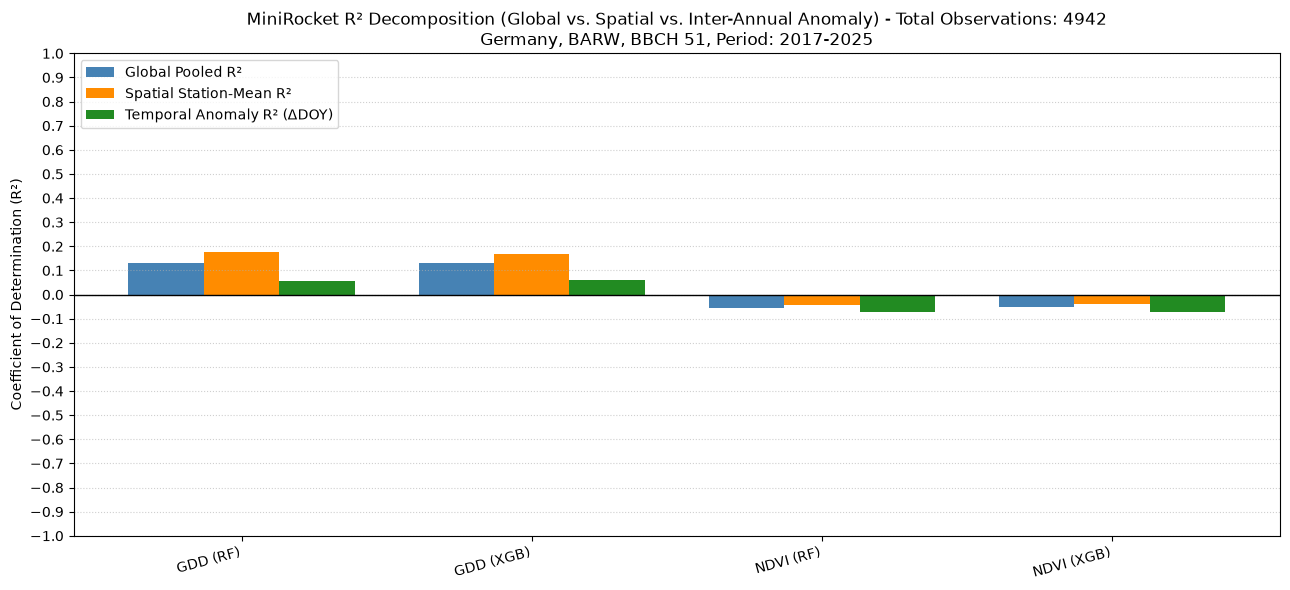

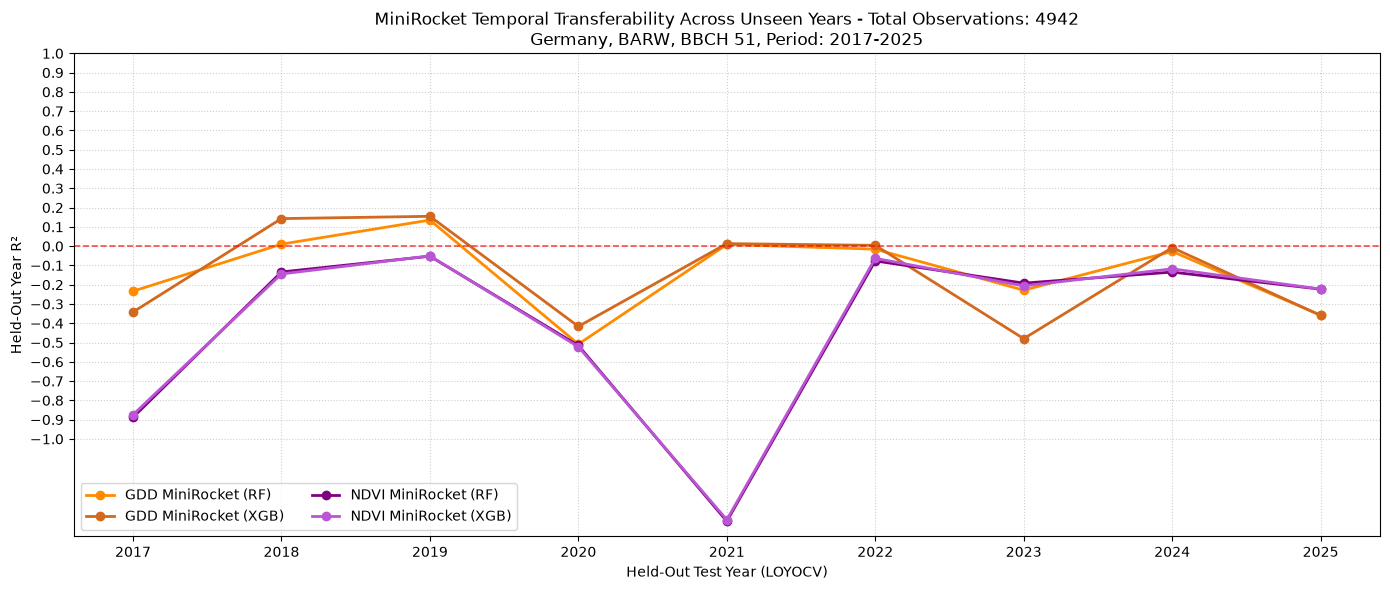

In [ ]:
from sklearn.metrics import r2_score

# Ensure actual_doy_rocket is a NumPy array for boolean masking
actual_doy_rocket_arr = np.asarray(actual_doy_rocket)

# Build station identifier from df_final to separate spatial vs. temporal variance
if "PEP_ID" in df_final.columns:
    station_ids = df_final["PEP_ID"].values
else:
    station_ids = (
        df_final["Latitude"].round(4).astype(str)
        + "_"
        + df_final["Longitude"].round(4).astype(str)
    ).values

years_arr = df_final["Year"].astype(int).values

rocket_r2_models = [
    ("GDD MiniRocket (RF)", np.asarray(rf_gdd_preds), "darkorange"),
    ("GDD MiniRocket (XGB)", np.asarray(xgb_gdd_preds), "chocolate"),
    ("NDVI MiniRocket (RF)", np.asarray(rf_ndvi_preds), "purple"),
    ("NDVI MiniRocket (XGB)", np.asarray(xgb_ndvi_preds), "mediumorchid"),
]

# R² Decomposition Plot: Global vs. Spatial vs. Temporal Anomaly R² (MiniRocket)
global_r2_list = []
spatial_r2_list = []
temporal_r2_list = []
short_labels = [
    "GDD (RF)",
    "GDD (XGB)",
    "NDVI (RF)",
    "NDVI (XGB)",
]
rocket_col_names = [
    "GDD_RF_R2",
    "GDD_XGB_R2",
    "NDVI_RF_R2",
    "NDVI_XGB_R2",
]

for _, preds, _ in rocket_r2_models:
    g_r2 = r2_score(actual_doy_rocket_arr, preds)

    df_tmp = pd.DataFrame({
        "Station": station_ids,
        "Actual": actual_doy_rocket_arr,
        "Pred": preds,
    })
    st_means = df_tmp.groupby("Station")[["Actual", "Pred"]].mean()
    s_r2 = r2_score(st_means["Actual"], st_means["Pred"])

    df_tmp = df_tmp.merge(st_means, on="Station", suffixes=("", "_mean"))
    obs_anom = df_tmp["Actual"] - df_tmp["Actual_mean"]
    pred_anom = df_tmp["Pred"] - df_tmp["Pred_mean"]
    t_r2 = r2_score(obs_anom, pred_anom)

    global_r2_list.append(g_r2)
    spatial_r2_list.append(s_r2)
    temporal_r2_list.append(t_r2)

# Save R² Decomposition values to CSV
df_r2_decomposition = pd.DataFrame({
    "Model_Label": short_labels,
    "Global_Pooled_R2": np.round(global_r2_list, 4),
    "Spatial_Station_Mean_R2": np.round(spatial_r2_list, 4),
    "Temporal_Anomaly_R2": np.round(temporal_r2_list, 4),
})
display(df_r2_decomposition)
df_r2_decomposition.to_csv(
    results_dir_rocket / "r2_decomposition_minirocket.csv",
    sep=";",
    index=False,
)

x_pos = np.arange(len(rocket_r2_models))
bar_width = 0.26

plt.figure(figsize=(13, 6))
plt.bar(
    x_pos - bar_width,
    global_r2_list,
    width=bar_width,
    label="Global Pooled R²",
    color="steelblue",
)
plt.bar(
    x_pos,
    spatial_r2_list,
    width=bar_width,
    label="Spatial Station-Mean R²",
    color="darkorange",
)
plt.bar(
    x_pos + bar_width,
    temporal_r2_list,
    width=bar_width,
    label="Temporal Anomaly R² (ΔDOY)",
    color="forestgreen",
)

plt.axhline(0, color="black", lw=1.0)
plt.xticks(x_pos, short_labels, rotation=15, ha="right")
plt.yticks(y_ticks)
plt.ylabel("Coefficient of Determination (R²)")
plt.title(
    f"MiniRocket R² Decomposition (Global vs. Spatial vs. Inter-Annual Anomaly) - "
    f"Total Observations: {len(df_final)}\n{final_name}"
)
plt.grid(True, axis="y", linestyle=":", alpha=0.6)
plt.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.savefig(
    results_dir_rocket / "r2_decomposition_minirocket.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# Per-Year LOYOCV R² Trajectory Across Held-Out Years (MiniRocket)
unique_years_plot = sorted(np.unique(years_arr))
df_r2_per_year = pd.DataFrame({"Test_Year": unique_years_plot})

plt.figure(figsize=(14, 6))

for col_name, (m_label, preds, color) in zip(rocket_col_names, rocket_r2_models):
    yearly_r2 = []
    for yr in unique_years_plot:
        mask = years_arr == yr
        yearly_r2.append(r2_score(actual_doy_rocket_arr[mask], preds[mask]))

    df_r2_per_year[col_name] = np.round(yearly_r2, 4)

    plt.plot(
        unique_years_plot,
        yearly_r2,
        marker="o",
        lw=2,
        color=color,
        label=m_label,
    )

# Save Per-Year R² values to CSV
display(df_r2_per_year)
df_r2_per_year.to_csv(
    results_dir_rocket / "r2_per_year_minirocket_leakage_free.csv",
    sep=";",
    index=False,
)

plt.axhline(0, color="red", linestyle="--", lw=1.2, alpha=0.7)
plt.title(
    f"MiniRocket Temporal Transferability Across Unseen Years - "
    f"Total Observations: {len(df_final)}\n{final_name}"
)
plt.xlabel("Held-Out Test Year (LOYOCV)")
plt.ylabel("Held-Out Year R²")
plt.xticks(unique_years_plot)
plt.yticks(y_ticks)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower left", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    results_dir_rocket / "r2_per_year_minirocket_leakage_free.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()